# Chapter 2: Dataset & Preprocessing
### Heart Disease Prediction Using Support Vector Machine (SVM)

This chapter presents the dataset and preprocessing procedures used for the heart disease prediction model. It covers dataset description, data cleaning, analytical objectives, machine learning problem formulation, feature engineering, data transformation, and the train/test strategy.

## 2.1 Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Regression models used only for the imputation-method comparison below
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, BayesianRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline

!ls '/content/drive/MyDrive/Machine Learning Assignment/'
df = pd.read_csv('/content/drive/MyDrive/Machine Learning Assignment/heart.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
'data mining 1.ipynb'  'data mining.ipynb'   heart.csv


In [ ]:
# Display first 5 rows
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 2.2 Dataset Description

### Source
This dataset is a combined **Heart Disease UCI dataset**, hosted on Kaggle
(`heart.csv`, "Heart Failure Prediction Dataset"), which merges five older
heart-disease datasets from the UCI Machine Learning Repository (Cleveland,
Hungary, Switzerland, Long Beach VA, and Stalog) into a single file of 918
unique patient records.

### What it contains
The dataset contains **918 patient records** described by **11 clinical
features** and **1 target variable** (`HeartDisease`).

| Column | Description |
|---|---|
| Age | Age of the patient (years) |
| Sex | Sex of the patient (M / F) |
| ChestPainType | Chest pain type (TA, ATA, NAP, ASY) |
| RestingBP | Resting blood pressure (mm Hg) |
| Cholesterol | Serum cholesterol (mm/dl) |
| FastingBS | Fasting blood sugar (1 if > 120 mg/dl, else 0) |
| RestingECG | Resting electrocardiogram results (Normal, ST, LVH) |
| MaxHR | Maximum heart rate achieved |
| ExerciseAngina | Exercise-induced angina (Y / N) |
| Oldpeak | ST depression induced by exercise relative to rest |
| ST_Slope | Slope of the peak exercise ST segment (Up, Flat, Down) |
| **HeartDisease** | **Target** — 1 = heart disease present, 0 = normal |

In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (918, 12)


In [ ]:
# Column names
print("Columns:")
print(df.columns.tolist())

Columns:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


In [ ]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
# Statistical summary
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [ ]:
# First 10 rows
df.head(10)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [ ]:
# Last 10 rows
df.tail(10)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
908,63,M,ASY,140,187,0,LVH,144,Y,4.0,Up,1
909,63,F,ASY,124,197,0,Normal,136,Y,0.0,Flat,1
910,41,M,ATA,120,157,0,Normal,182,N,0.0,Up,0
911,59,M,ASY,164,176,1,LVH,90,N,1.0,Flat,1
912,57,F,ASY,140,241,0,Normal,123,Y,0.2,Flat,1
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


## 2.3 Data Cleaning

### 2.3.1 Check for conventional (NaN) missing values

In [ ]:
print("Missing values (conventional NaN):")
print(df.isnull().sum())

Missing values (conventional NaN):
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


2.3.2 Identify disguised missing values (BEFORE replacing)

> Cholesterol and RestingBP are clinical measurements that cannot
physiologically be zero. A value of 0 most likely indicates a
measurement that was not taken.



In [ ]:
cholesterol_zero = (df["Cholesterol"] == 0).sum()
restingbp_zero = (df["RestingBP"] == 0).sum()

print("Cholesterol = 0:", cholesterol_zero)
print("RestingBP = 0:", restingbp_zero)

Cholesterol = 0: 172
RestingBP = 0: 1


2.3.3 Convert disguised missing values to NaN

In [ ]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].replace(0, np.nan)

print("\nMissing values after converting disguised zeros to NaN:")
print(df.isnull().sum())



Missing values after converting disguised zeros to NaN:
Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
dtype: int64


2.3.4 Duplicate Check

In [ ]:
duplicate_count = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


2.3.5 Separate X / y, then Train/Test split
(Happen before imputation, to avoid data leakage)

In [ ]:
X = df.drop(columns=["HeartDisease"]).copy()
y = df["HeartDisease"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\nTraining set:", X_train.shape)
print("Testing set :", X_test.shape)



Training set: (734, 11)
Testing set : (184, 11)


2.3.6 Compare candidate imputation methods

> Fit only on rows with known Cholesterol from X_train, validated on a held-out slice of the SAME rows — X_test is never touched here



In [ ]:
train_known = X_train[X_train["Cholesterol"].notna()].copy()
chol_train, chol_validation = train_test_split(
    train_known, test_size=0.20, random_state=42
)

numerical_cols = ["Age", "RestingBP", "FastingBS", "MaxHR", "Oldpeak"]

# --- Global Median ---

In [ ]:
median_value = chol_train["Cholesterol"].median()
median_pred = np.full(len(chol_validation), median_value)
median_mae = mean_absolute_error(chol_validation["Cholesterol"], median_pred)
median_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], median_pred))

# --- Group Median (Sex + AgeGroup) ---

In [ ]:
sex_only_medians = chol_train.groupby("Sex")["Cholesterol"].median()
sex_only_pred = chol_validation["Sex"].map(sex_only_medians)
sex_only_mae = mean_absolute_error(chol_validation["Cholesterol"], sex_only_pred)

bins = [0, 40, 50, 60, 100]
labels = ["<40", "40-49", "50-59", "60+"]
chol_train_g = chol_train.copy()
chol_train_g["AgeGroup"] = pd.cut(chol_train_g["Age"], bins=bins, labels=labels)
chol_val_g = chol_validation.copy()
chol_val_g["AgeGroup"] = pd.cut(chol_val_g["Age"], bins=bins, labels=labels)

age_only_medians = chol_train_g.groupby("AgeGroup", observed=True)["Cholesterol"].median()
age_only_pred = chol_val_g["AgeGroup"].map(age_only_medians)
age_only_mae = mean_absolute_error(chol_validation["Cholesterol"], age_only_pred)

group_medians = chol_train_g.groupby(["Sex", "AgeGroup"], observed=True)["Cholesterol"].median()
group_pred = chol_val_g.apply(
    lambda r: group_medians.get((r["Sex"], r["AgeGroup"]), median_value), axis=1
).values
group_mae = mean_absolute_error(chol_validation["Cholesterol"], group_pred)
group_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], group_pred))

print("Sex only MAE:", sex_only_mae)
print("AgeGroup only MAE:", age_only_mae)
print("Sex × AgeGroup MAE:", group_mae)

Sex only MAE: 43.760330578512395
AgeGroup only MAE: 44.37190082644628
Sex × AgeGroup MAE: 43.78512396694215


In [ ]:
import scipy.stats as stats
n_splits = 30
sex_maes = []
age_maes = []
group_maes = []

bins = [0, 40, 50, 60, 100]
labels = ["<40", "40-49", "50-59", "60+"]

# Use the train_known dataset created earlier (where Cholesterol is not NaN)
print(f"Running {n_splits} independent train/val splits to test imputation robustness...")

for i in range(n_splits):
    # Create a new random split for each iteration
    c_train, c_val = train_test_split(train_known, test_size=0.20, random_state=i)

    # Bin Age into AgeGroup
    c_train = c_train.copy()
    c_val = c_val.copy()
    c_train["AgeGroup"] = pd.cut(c_train["Age"], bins=bins, labels=labels)
    c_val["AgeGroup"] = pd.cut(c_val["Age"], bins=bins, labels=labels)

    # Global fallback median (just in case a group is missing in the training set)
    fallback_median = c_train["Cholesterol"].median()

    # 1. Sex Only Imputation
    sex_medians = c_train.groupby("Sex")["Cholesterol"].median()
    sex_pred = c_val["Sex"].map(sex_medians).fillna(fallback_median)
    sex_maes.append(mean_absolute_error(c_val["Cholesterol"], sex_pred))

    # 2. AgeGroup Only Imputation
    age_medians = c_train.groupby("AgeGroup", observed=True)["Cholesterol"].median()
    age_pred = c_val["AgeGroup"].map(age_medians).astype(float).fillna(fallback_median)
    age_maes.append(mean_absolute_error(c_val["Cholesterol"], age_pred))

    # 3. Sex * AgeGroup Imputation
    group_medians = c_train.groupby(["Sex", "AgeGroup"], observed=True)["Cholesterol"].median()
    group_pred = c_val.apply(lambda r: group_medians.get((r["Sex"], r["AgeGroup"]), fallback_median), axis=1)
    group_maes.append(mean_absolute_error(c_val["Cholesterol"], group_pred.values))

mean_sex_mae = np.mean(sex_maes)
mean_age_mae = np.mean(age_maes)
mean_group_mae = np.mean(group_maes)

# Calculate how many times Group beat Sex
group_wins = sum(np.array(group_maes) < np.array(sex_maes))

# Paired t-test (Sex vs Group)
t_stat, p_val = stats.ttest_rel(sex_maes, group_maes)

print("-" * 50)
print(f"--- {n_splits} Random Splits Evaluation Results ---")
print(f"AgeGroup-only Mean MAE : {mean_age_mae:.2f}")
print(f"Sex-only Mean MAE      : {mean_sex_mae:.2f}")
print(f"Sex*AgeGroup Mean MAE  : {mean_group_mae:.2f}")
print("-" * 50)
print(f"Sex*AgeGroup Wins over Sex-only: {group_wins} / {n_splits} ({(group_wins/n_splits)*100:.1f} generalised MAE across random splits.")
print(f"Paired t-test (Sex vs Group)   : t = {t_stat:.2f}, p-value = {p_val:.4f}")
print("-" * 50)

if p_val < 0.05 and mean_group_mae < mean_sex_mae:
    print("Conclusion: Sex*AgeGroup is STATISTICALLY SIGNIFICANTLY better than Sex-only.")
else:
    print("Conclusion: No statistically significant improvement across 30 splits.")

Running 30 independent train/val splits to test imputation robustness...
--------------------------------------------------
--- 30 Random Splits Evaluation Results ---
AgeGroup-only Mean MAE : 43.48
Sex-only Mean MAE      : 42.99
Sex*AgeGroup Mean MAE  : 42.28
--------------------------------------------------
Sex*AgeGroup Wins over Sex-only: 25 / 30 (83.3 generalised MAE across random splits.
Paired t-test (Sex vs Group)   : t = 4.26, p-value = 0.0002
--------------------------------------------------
Conclusion: Sex*AgeGroup is STATISTICALLY SIGNIFICANTLY better than Sex-only.


In [ ]:
bins = [0, 40, 50, 60, 100]
labels = ["<40", "40-49", "50-59", "60+"]
chol_train_g = chol_train.copy()
chol_train_g["AgeGroup"] = pd.cut(chol_train_g["Age"], bins=bins, labels=labels)
chol_val_g = chol_validation.copy()
chol_val_g["AgeGroup"] = pd.cut(chol_val_g["Age"], bins=bins, labels=labels)

group_medians = chol_train_g.groupby(["Sex", "AgeGroup"], observed=True)["Cholesterol"].median()
group_pred = chol_val_g.apply(
    lambda r: group_medians.get((r["Sex"], r["AgeGroup"]), median_value), axis=1
).values
group_mae = mean_absolute_error(chol_validation["Cholesterol"], group_pred)
group_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], group_pred))

# --- KNN ---

In [ ]:
knn_model = Pipeline([("scaler", StandardScaler()),
                       ("model", KNeighborsRegressor(n_neighbors=5, weights="distance"))])
knn_model.fit(chol_train[numerical_cols], chol_train["Cholesterol"])
knn_pred = knn_model.predict(chol_validation[numerical_cols])
knn_mae = mean_absolute_error(chol_validation["Cholesterol"], knn_pred)
knn_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], knn_pred))

# --- Linear Regression ---

In [ ]:
linear_model = Pipeline([("scaler", StandardScaler()),
                          ("model", LinearRegression())])
linear_model.fit(chol_train[numerical_cols], chol_train["Cholesterol"])
linear_pred = linear_model.predict(chol_validation[numerical_cols])
linear_mae = mean_absolute_error(chol_validation["Cholesterol"], linear_pred)
linear_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], linear_pred))

# --- Random Forest ---

In [ ]:
rf_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]),
    ("num", StandardScaler(), numerical_cols)
])
rf_features = numerical_cols + ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
rf_model = Pipeline([("preprocessor", rf_preprocessor),
                      ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])
rf_model.fit(chol_train[rf_features], chol_train["Cholesterol"])
rf_pred = rf_model.predict(chol_validation[rf_features])
rf_mae = mean_absolute_error(chol_validation["Cholesterol"], rf_pred)
rf_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], rf_pred))

# --- MICE ---

In [ ]:
mice_features = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]
mice_train = chol_train[mice_features].copy()
mice_val_missing = chol_validation[mice_features].copy()
mice_val_missing["Cholesterol"] = np.nan
mice = IterativeImputer(estimator=BayesianRidge(), max_iter=20, random_state=42)
mice.fit(mice_train)
mice_result = mice.transform(mice_val_missing)
mice_pred = mice_result[:, mice_features.index("Cholesterol")]
mice_mae = mean_absolute_error(chol_validation["Cholesterol"], mice_pred)
mice_rmse = np.sqrt(mean_squared_error(chol_validation["Cholesterol"], mice_pred))

# --- Comparison Table and Chart  ---



In [ ]:
comparison = pd.DataFrame({
    "Method": ["Global Median", "Group Median (Sex+AgeGroup)", "KNN", "Linear Regression", "Random Forest", "MICE"],
    "MAE":  [median_mae, group_mae, knn_mae, linear_mae, rf_mae, mice_mae],
    "RMSE": [median_rmse, group_rmse, knn_rmse, linear_rmse, rf_rmse, mice_rmse]
}).sort_values("MAE").reset_index(drop=True)

print("\nCholesterol Imputation Method Comparison:")
print(comparison)


Cholesterol Imputation Method Comparison:
                        Method        MAE       RMSE
0  Group Median (Sex+AgeGroup)  43.785124  58.125896
1                         MICE  44.367970  59.846090
2            Linear Regression  44.382381  60.086108
3                Global Median  44.677686  60.317754
4                Random Forest  45.773499  60.212479
5                          KNN  50.601744  66.334144


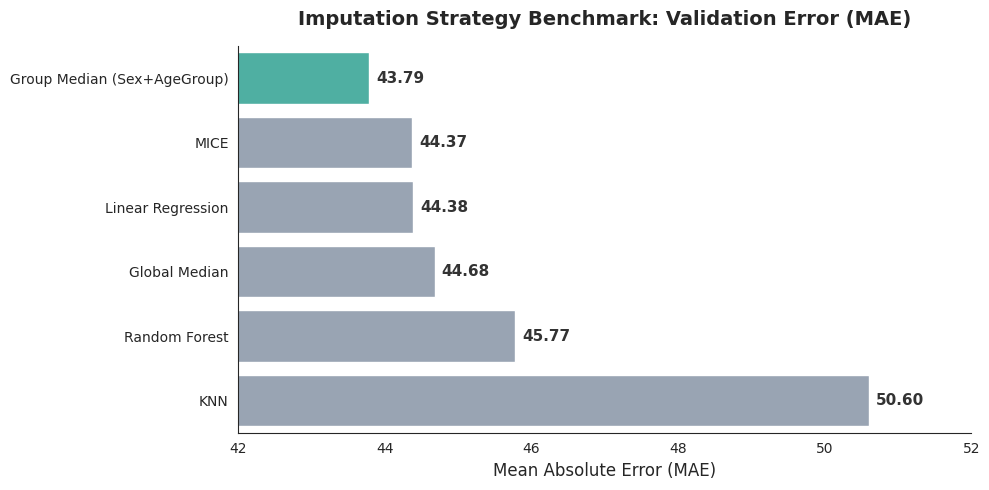

In [ ]:
plt.figure(figsize=(10, 5))

colors = ['#3FBFAD'] + ['#94a3b8'] * (len(comparison) - 1)
ax = sns.barplot(x="MAE", y="Method", data=comparison, palette=colors)

plt.xlim(42, 52)

# Formatting the chart to look professional
plt.title("Imputation Strategy Benchmark: Validation Error (MAE)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mean Absolute Error (MAE)", fontsize=12)
plt.ylabel("")

# Add the exact numbers at the end of each bar for precision
for p in ax.patches:
    ax.annotate(f'{p.get_width():.2f}',
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0), textcoords='offset points',
                fontsize=11, fontweight='bold', color='#333333')

# Remove top and right borders for a cleaner look
sns.despine()

plt.tight_layout()
plt.show()

Group Median (Sex + AgeGroup) achieves the lowest MAE/RMSE, and is
selected as the final imputation method: simple, transparent, no leakage risk, and no meaningful accuracy trade-off vs. more complex models (the small gap confirms Cholesterol has weak linear/non-linear relationship with the other clinical features — consistent with this dataset's known multi-source collection artifacts).

2.3.7 Final Imputation: Group Median (Sex + AgeGroup)


> Fit medians on X_train ONLY, apply to both X_train and X_test



In [ ]:
# Record missingness flag BEFORE imputing (captures potential MNAR signal)
X_train["Cholesterol_Missing"] = X_train["Cholesterol"].isna().astype(int)
X_test["Cholesterol_Missing"]  = X_test["Cholesterol"].isna().astype(int)

X_train["AgeGroup"] = pd.cut(X_train["Age"], bins=bins, labels=labels)
X_test["AgeGroup"]  = pd.cut(X_test["Age"], bins=bins, labels=labels)

final_group_medians = X_train.groupby(["Sex", "AgeGroup"], observed=True)["Cholesterol"].median()
final_fallback = X_train["Cholesterol"].median()
bp_median = X_train["RestingBP"].median()

def fill_cholesterol(row):
    if pd.isna(row["Cholesterol"]):
        return final_group_medians.get((row["Sex"], row["AgeGroup"]), final_fallback)
    return row["Cholesterol"]

X_train["Cholesterol"] = X_train.apply(fill_cholesterol, axis=1)
X_test["Cholesterol"]  = X_test.apply(fill_cholesterol, axis=1)

X_train["RestingBP"] = X_train["RestingBP"].fillna(bp_median)
X_test["RestingBP"]  = X_test["RestingBP"].fillna(bp_median)

print("\nMissing values after final imputation (train):")
print(X_train.isnull().sum())
print("\nMissing values after final imputation (test):")
print(X_test.isnull().sum())

print("\nDuplicate rows — train:", X_train.duplicated().sum())
print("Duplicate rows — test :", X_test.duplicated().sum())

print("\nTarget distribution — train:")
print(y_train.value_counts(normalize=True))
print("\nTarget distribution — test:")
print(y_test.value_counts(normalize=True))


Missing values after final imputation (train):
Age                    0
Sex                    0
ChestPainType          0
RestingBP              0
Cholesterol            0
FastingBS              0
RestingECG             0
MaxHR                  0
ExerciseAngina         0
Oldpeak                0
ST_Slope               0
Cholesterol_Missing    0
AgeGroup               0
dtype: int64

Missing values after final imputation (test):
Age                    0
Sex                    0
ChestPainType          0
RestingBP              0
Cholesterol            0
FastingBS              0
RestingECG             0
MaxHR                  0
ExerciseAngina         0
Oldpeak                0
ST_Slope               0
Cholesterol_Missing    0
AgeGroup               0
dtype: int64

Duplicate rows — train: 0
Duplicate rows — test : 0

Target distribution — train:
HeartDisease
1    0.553134
0    0.446866
Name: proportion, dtype: float64

Target distribution — test:
HeartDisease
1    0.554348
0    0.445652
Na

# 2.3.8 Validate Imputation: Distribution Before vs After

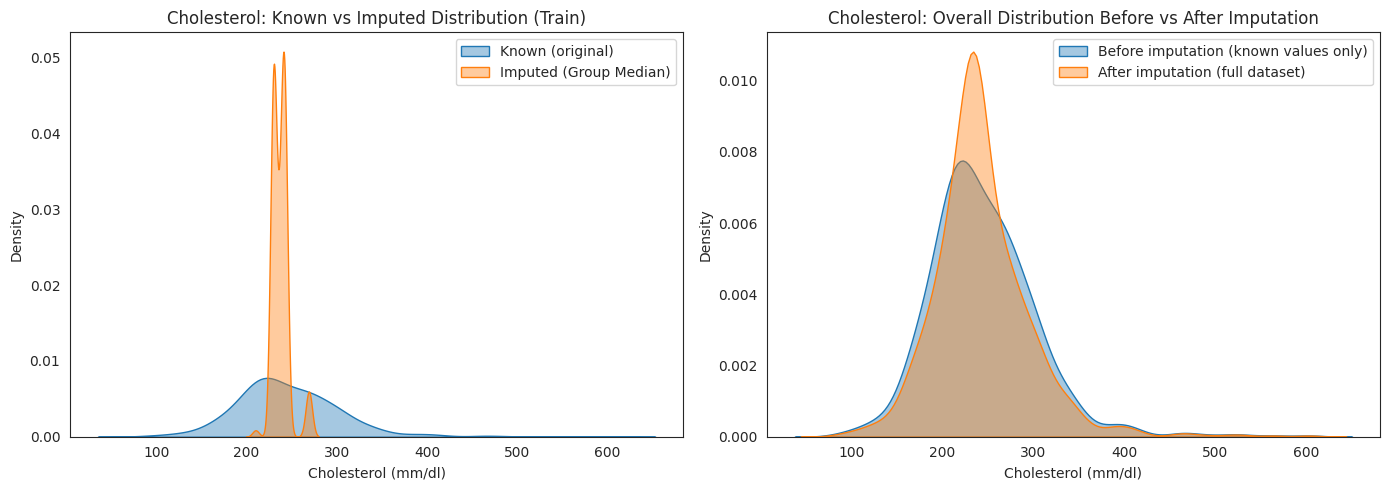

Known Cholesterol stats:
 count    605.000000
mean     246.560331
std       59.656537
min       85.000000
25%      210.000000
50%      238.000000
75%      277.000000
max      603.000000
Name: Cholesterol, dtype: float64

Imputed Cholesterol stats:
 count    129.000000
mean     237.434109
std        9.585833
min      210.000000
25%      230.000000
50%      238.000000
75%      242.000000
max      269.000000
Name: Cholesterol, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Cholesterol distribution (known values only) vs (imputed values only)

known_train_chol = X_train.loc[X_train["Cholesterol_Missing"] == 0, "Cholesterol"]
imputed_train_chol = X_train.loc[X_train["Cholesterol_Missing"] == 1, "Cholesterol"]

sns.kdeplot(known_train_chol, label="Known (original)", fill=True, alpha=0.4, ax=axes[0])
sns.kdeplot(imputed_train_chol, label="Imputed (Group Median)", fill=True, alpha=0.4, ax=axes[0])
axes[0].set_title("Cholesterol: Known vs Imputed Distribution (Train)")
axes[0].set_xlabel("Cholesterol (mm/dl)")
axes[0].legend()

# Right: Overall Cholesterol distribution before vs after imputation

before = pd.concat([known_train_chol, X_test.loc[X_test["Cholesterol_Missing"] == 0, "Cholesterol"]])
after = pd.concat([X_train["Cholesterol"], X_test["Cholesterol"]])

sns.kdeplot(before, label="Before imputation (known values only)", fill=True, alpha=0.4, ax=axes[1])
sns.kdeplot(after, label="After imputation (full dataset)", fill=True, alpha=0.4, ax=axes[1])
axes[1].set_title("Cholesterol: Overall Distribution Before vs After Imputation")
axes[1].set_xlabel("Cholesterol (mm/dl)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Known Cholesterol stats:\n", known_train_chol.describe())
print("\nImputed Cholesterol stats:\n", imputed_train_chol.describe())


## 2.4 Feature Engineering

### 2.4.1 Identify categorical and numerical variables

In [ ]:
categorical_features = [
    "Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope", "AgeGroup"
]

numerical_features = [
    "Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak",
    "Cholesterol_Missing", "HR_Achievement_Ratio", "Is_ASY"
]

target = "HeartDisease"

# Inspect categories inside each categorical feature
for column in ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]:
    print(f"\n{column}:")
    print(X_train[column].unique())


Sex:
['M' 'F']

ChestPainType:
['ATA' 'ASY' 'NAP' 'TA']

RestingECG:
['ST' 'Normal' 'LVH']

ExerciseAngina:
['Y' 'N']

ST_Slope:
['Flat' 'Up' 'Down']


### 2.4.2 Engineered feature: `AgeGroup`

AgeGroup bins patients into clinically meaningful brackets (<40, 40-49, 50-59, 60+), helping the model capture non-linear age-related risk (risk rises sharply after 50) that raw Age alone may not represent as clearly. Already generated in X_train/X_test.

In [ ]:

print("\nAgeGroup distribution (train):")
print(X_train["AgeGroup"].value_counts())


AgeGroup distribution (train):
AgeGroup
50-59    300
60+      188
40-49    172
<40       74
Name: count, dtype: int64


# 2.4.3 Engineered feature: Cholesterol_Missing

Binary flag (1 = Cholesterol was originally missing/0, 0 = originally recorded). Captures the possibility that missingness itself carries signal (e.g. tied to which source sub-dataset a record came from) since our comparison in 2.3.6 showed no regression method could meaningfully predict the true value from other clinical features.


In [ ]:
print("\nCholesterol_Missing distribution (train):")
print(X_train["Cholesterol_Missing"].value_counts())


Cholesterol_Missing distribution (train):
Cholesterol_Missing
0    605
1    129
Name: count, dtype: int64


# 2.4.4 Engineered feature: HR_Achievement_Ratio

Ratio of achieved MaxHR to the age-predicted maximum heart rate (220 - Age). A value close to 1 suggests the patient reached close to their theoretical max HR during the stress test; a low ratio can indicate reduced cardiac exercise capacity, which is clinically relevant to heart disease risk.

In [ ]:
X_train["HR_Achievement_Ratio"] = X_train["MaxHR"] / (220 - X_train["Age"])
X_test["HR_Achievement_Ratio"]  = X_test["MaxHR"] / (220 - X_test["Age"])

print("\nHR_Achievement_Ratio summary (train):")
print(X_train["HR_Achievement_Ratio"].describe())


HR_Achievement_Ratio summary (train):
count    734.000000
mean       0.819992
std        0.144168
min        0.355030
25%        0.723270
50%        0.824734
75%        0.933533
max        1.140127
Name: HR_Achievement_Ratio, dtype: float64


# 2.4.5 Engineered feature: Is_ASY

Binary flag for ChestPainType == "ASY" (asymptomatic). Clinically, asymptomatic chest pain is associated with a HIGHER risk of heart disease (silent ischemia), which is counter-intuitive — this flag lets the model isolate that specific high-risk category directly.

In [ ]:
X_train["Is_ASY"] = (X_train["ChestPainType"] == "ASY").astype(int)
X_test["Is_ASY"]  = (X_test["ChestPainType"] == "ASY").astype(int)

print("\nIs_ASY distribution (train):")
print(X_train["Is_ASY"].value_counts())


Is_ASY distribution (train):
Is_ASY
1    403
0    331
Name: count, dtype: int64


# Final feature check

In [ ]:
print("\nFinal X_train columns:", X_train.columns.tolist())
print("Final X_train shape:", X_train.shape)
print("Final X_test shape :", X_test.shape)


Final X_train columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'Cholesterol_Missing', 'AgeGroup', 'HR_Achievement_Ratio', 'Is_ASY']
Final X_train shape: (734, 15)
Final X_test shape : (184, 15)


In [ ]:
# 2.4.6 Ablation Study: Validating Engineered Features
# Compare CV ROC-AUC with vs without each engineered feature to confirm
# they add real predictive value, not just correlation with the target.

from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

def ablation_score(num_extra, cat_extra, label):
    num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"] + num_extra
    cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"] + cat_extra
    ct = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ])
    pipe = Pipeline([("prep", ct), ("svm", SVC(kernel="rbf", probability=True, random_state=42))])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    print(f"{label:40s} CV ROC-AUC = {scores.mean():.4f}")

ablation_score([], [], "Baseline (raw features only)")
ablation_score(["HR_Achievement_Ratio"], [], "+ HR_Achievement_Ratio")
ablation_score(["Cholesterol_Missing"], [], "+ Cholesterol_Missing")
ablation_score([], ["AgeGroup"], "+ AgeGroup")
ablation_score(["Is_ASY"], [], "+ Is_ASY")
ablation_score(["HR_Achievement_Ratio","Cholesterol_Missing","Is_ASY"], ["AgeGroup"], "All 4 combined")

Baseline (raw features only)             CV ROC-AUC = 0.9080
+ HR_Achievement_Ratio                   CV ROC-AUC = 0.9088
+ Cholesterol_Missing                    CV ROC-AUC = 0.9160
+ AgeGroup                               CV ROC-AUC = 0.9085
+ Is_ASY                                 CV ROC-AUC = 0.9108
All 4 combined                           CV ROC-AUC = 0.9179


## 2.5 Data Transformation

Two transformations are required before modelling:

- **Numerical features → `StandardScaler`**: SVM is a distance-based
  algorithm, so it is sensitive to feature scale. Without scaling, a feature
  like `Cholesterol` (values in the hundreds) would dominate the decision
  boundary over a feature like `FastingBS` (values of 0 or 1). Standardizing
  all numerical features to zero mean and unit variance ensures each feature
  contributes fairly.
- **Categorical features → `OneHotEncoder`**: converts nominal categories
  (e.g., `Sex`, `ChestPainType`) into binary indicator columns so they can be
  used by the model. `drop="first"` avoids redundant (multicollinear) columns,
  and `handle_unknown="ignore"` prevents errors if the test/validation set
  contains an unseen category.

Both transformations are combined using a single `ColumnTransformer`, which
will later be embedded inside a `Pipeline` together with the SVM model in
Chapter 4. This keeps preprocessing and modelling as one unit and prevents
data leakage, since the scaler/encoder will only be fit on the training data
during cross-validation, never on the test data.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features)
    ]
)

preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'RestingBP', 'Cholesterol',
                                  'FastingBS', 'MaxHR', 'Oldpeak',
                                  'Cholesterol_Missing', 'HR_Achievement_Ratio',
                                  'Is_ASY']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['Sex', 'ChestPainType', 'RestingECG',
                                  'ExerciseAngina', 'ST_Slope', 'AgeGroup'])])

In [ ]:
from sklearn.base import clone
preview = clone(preprocessor).fit_transform(X_train[numerical_features + categorical_features])
print("Transformed X_train shape (preview only):", preview.shape)

Transformed X_train shape (preview only): (734, 21)


## 2.6 Train/Test Strategy

The dataset was divided into **80% training data and 20% testing data** using
`train_test_split()`. A `random_state` of 42 was used to ensure
reproducibility. **Stratification** was applied on the `HeartDisease` target
variable so that the proportion of patients with and without heart disease
remains approximately consistent between the training and testing sets. This
matters here because the classes are only mildly imbalanced (about
55% / 45%), and stratifying prevents either split from accidentally being
skewed.

Note: `preprocessor` (the `ColumnTransformer` defined above) is **not fitted
yet** — it will only be fit on `X_train` inside the model `Pipeline` in
Chapter 4, so that no information from the test set leaks into the scaling or
encoding process.

In [ ]:
print("Train/Test Strategy Summary")
print("=" * 60)
print(f"Split ratio       : 80% train / 20% test")
print(f"random_state      : 42 (reproducibility)")
print(f"Stratification    : on HeartDisease target")
print(f"Training set size : {X_train.shape[0]} rows")
print(f"Testing set size  : {X_test.shape[0]} rows")
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Train/Test Strategy Summary
Split ratio       : 80% train / 20% test
random_state      : 42 (reproducibility)
Stratification    : on HeartDisease target
Training set size : 734 rows
Testing set size  : 184 rows

Training target distribution:
HeartDisease
1    0.5531
0    0.4469
Name: proportion, dtype: float64

Testing target distribution:
HeartDisease
1    0.5543
0    0.4457
Name: proportion, dtype: float64


In [ ]:
# Verify class proportions are preserved across the split
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
HeartDisease
1    0.553134
0    0.446866
Name: proportion, dtype: float64

Testing target distribution:
HeartDisease
1    0.554348
0    0.445652
Name: proportion, dtype: float64


# Chapter 3: Exploratory Data Analysis
### Heart Disease Prediction Using Support Vector Machine (SVM)

With the dataset cleaned, imputed, and feature-engineered in Chapter 2, this chapter explores
the data to understand *which clinical signals actually separate patients with heart disease
from patients without it*. As the data science team on this engagement, our goal here is not
just to describe the data, but to build the evidence base that will justify our model choice
and hyperparameters in Chapter 4 — i.e. to answer the client's real question: *"which of these
11 clinical measurements should the model be listening to, and how strongly?"*

**Important methodological note:** all analysis in this chapter is performed on `X_train` /
`y_train` **only**. `X_test` is intentionally left untouched. Deriving insights from the test
set — even just by looking at it — risks unconsciously shaping our feature and model choices
around data the model will later be evaluated on, defeating the purpose of a held-out test
set.

In [ ]:
# Recombine the processed training features with the training target for EDA purposes only.
# X_test / y_test are NOT touched anywhere in this chapter.
train_eda = X_train.copy()
train_eda["HeartDisease"] = y_train.values

print("EDA working set shape:", train_eda.shape)
train_eda.head()

EDA working set shape: (734, 16)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Cholesterol_Missing,AgeGroup,HR_Achievement_Ratio,Is_ASY,HeartDisease
485,63,M,ATA,139.0,217.0,1,ST,128,Y,1.2,Flat,0,60+,0.815287,0,1
486,55,M,ATA,110.0,214.0,1,ST,180,N,0.4,Up,0,50-59,1.090909,0,0
117,59,F,ASY,130.0,338.0,1,ST,130,Y,1.5,Flat,0,50-59,0.807453,1,1
361,47,M,ASY,160.0,238.0,0,Normal,124,Y,0.0,Flat,1,40-49,0.716763,1,1
296,50,M,ASY,145.0,238.0,1,Normal,139,Y,0.7,Flat,1,40-49,0.817647,1,1


## 3.1 Statistical Summary

### 3.1.1 Overall distribution of numerical features (training set, post-cleaning)

In [ ]:
train_eda[numerical_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,734.0,53.85,9.44,29.00,47.00,55.00,61.00,77.00
RestingBP,734.0,132.87,18.08,92.00,120.00,130.00,141.00,200.00
Cholesterol,734.0,244.96,54.41,85.00,215.00,238.00,269.75,603.00
FastingBS,734.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
MaxHR,734.0,136.38,25.83,60.00,119.00,138.00,156.00,202.00
Oldpeak,734.0,0.87,1.06,-2.60,0.00,0.50,1.50,5.60
Cholesterol_Missing,734.0,0.18,0.38,0.00,0.00,0.00,0.00,1.00
HR_Achievement_Ratio,734.0,0.82,0.14,0.36,0.72,0.82,0.93,1.14
Is_ASY,734.0,0.55,0.50,0.00,0.00,1.00,1.00,1.00


### 3.1.2 Numerical features split by class

The overall summary above tells us the shape of each feature, but it hides the thing we
actually care about: *does this feature look different for patients who have heart disease
versus patients who don't?* The table below answers that directly by comparing the mean of
each numerical feature between the two classes.

In [ ]:
class_means = train_eda.groupby("HeartDisease")[numerical_features].mean().round(2).T
class_means.columns = ["No Disease (0)", "Disease (1)"]
class_means["Difference"] = (class_means["Disease (1)"] - class_means["No Disease (0)"]).round(2)
class_means.sort_values("Difference", key=abs, ascending=False)

,No Disease (0),Disease (1),Difference
MaxHR,148.07,126.93,-21.14
Cholesterol,241.80,247.51,5.71
Age,51.28,55.92,4.64
RestingBP,130.82,134.53,3.71
Oldpeak,0.42,1.22,0.80
Is_ASY,0.26,0.78,0.52
Cholesterol_Missing,0.04,0.29,0.25
FastingBS,0.11,0.33,0.22
HR_Achievement_Ratio,0.88,0.77,-0.11


**Reading the table:** patients with heart disease have, on average, a noticeably **lower
Max Heart Rate (~127 vs ~148 bpm)**, a higher **Oldpeak / ST depression (~1.22 vs ~0.42)**,
are on average **older (~56 vs ~51)**, and are **far more likely to have the engineered
`Is_ASY` flag = 1 (78% vs 26%)**. Interestingly, raw `Cholesterol` shows almost no difference
between classes (241.8 vs 247.5) — we investigate this further in Section 3.2.

### 3.1.3 Categorical features split by class (disease rate per category)

In [ ]:
for col in categorical_features:
    rate = train_eda.groupby(col, observed=True)["HeartDisease"].agg(["mean", "count"]).round(3)
    rate.columns = ["HeartDisease Rate", "N"]
    print(f"--- {col} ---")
    print(rate.sort_values("HeartDisease Rate", ascending=False))
    print()

--- Sex ---
     HeartDisease Rate    N
Sex                        
M                0.625  579
F                0.284  155

--- ChestPainType ---
               HeartDisease Rate    N
ChestPainType                        
ASY                        0.787  403
TA                         0.450   40
NAP                        0.335  155
ATA                        0.140  136

--- RestingECG ---
            HeartDisease Rate    N
RestingECG                        
ST                      0.660  141
LVH                     0.575  146
Normal                  0.512  447

--- ExerciseAngina ---
                HeartDisease Rate    N
ExerciseAngina                        
Y                           0.847  300
N                           0.350  434

--- ST_Slope ---
          HeartDisease Rate    N
ST_Slope                        
Flat                  0.832  374
Down                  0.830   47
Up                    0.179  313

--- AgeGroup ---
          HeartDisease Rate    N
AgeGroup        

## 3.2 Correlation Analysis

### 3.2.1 Numerical feature correlation matrix

Note that `HeartDisease` is a binary (0/1) target, so a standard Pearson correlation with it
is mathematically equivalent to a **point-biserial correlation** — this is valid and
commonly used, but it only captures *linear* association. We treat correlations with the
target as a screening signal, not a final verdict on a feature's usefulness (a feature can be
non-linearly predictive with a low Pearson correlation).

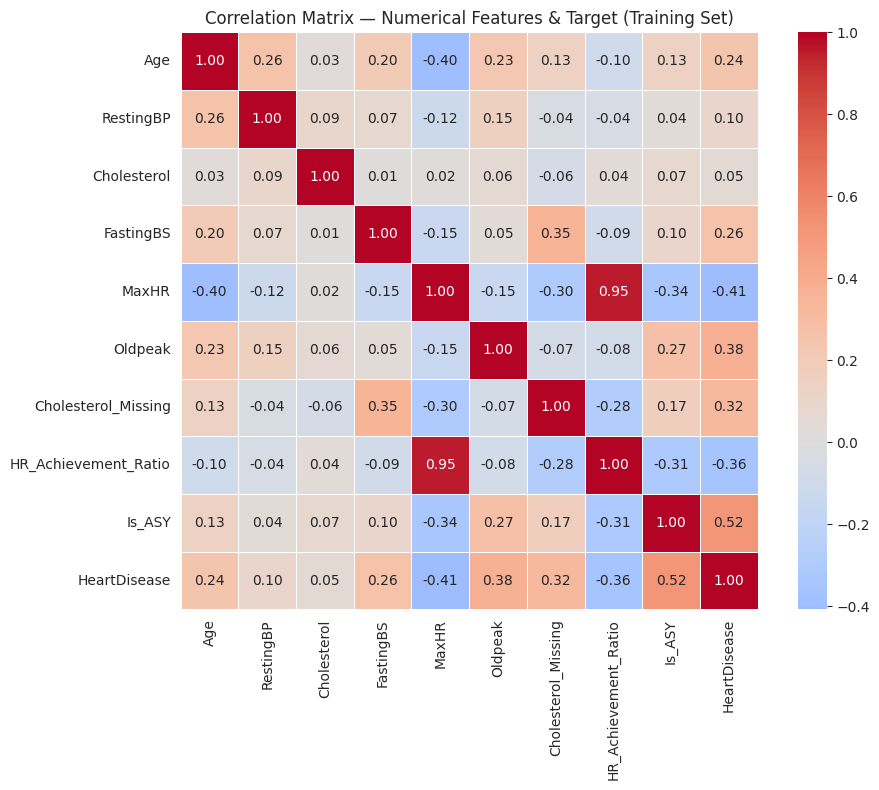

In [ ]:
plt.figure(figsize=(10, 8))
corr_matrix = train_eda[numerical_features + ["HeartDisease"]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=True)
plt.title("Correlation Matrix — Numerical Features & Target (Training Set)")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import pointbiserialr

pb_results = {}
for col in numerical_features:
    r, p_value = pointbiserialr(train_eda["HeartDisease"], train_eda[col])
    pb_results[col] = {"correlation": round(r, 3), "p_value": round(p_value, 4)}

pb_df = pd.DataFrame(pb_results).T.sort_values("correlation", key=abs, ascending=False)
print("Point-biserial correlation with HeartDisease (sorted by strength):")
pb_df

Point-biserial correlation with HeartDisease (sorted by strength):


,correlation,p_value
Is_ASY,0.518,0.0000
MaxHR,-0.407,0.0000
Oldpeak,0.377,0.0000
HR_Achievement_Ratio,-0.357,0.0000
Cholesterol_Missing,0.321,0.0000
FastingBS,0.261,0.0000
Age,0.245,0.0000
RestingBP,0.102,0.0057
Cholesterol,0.052,0.1574


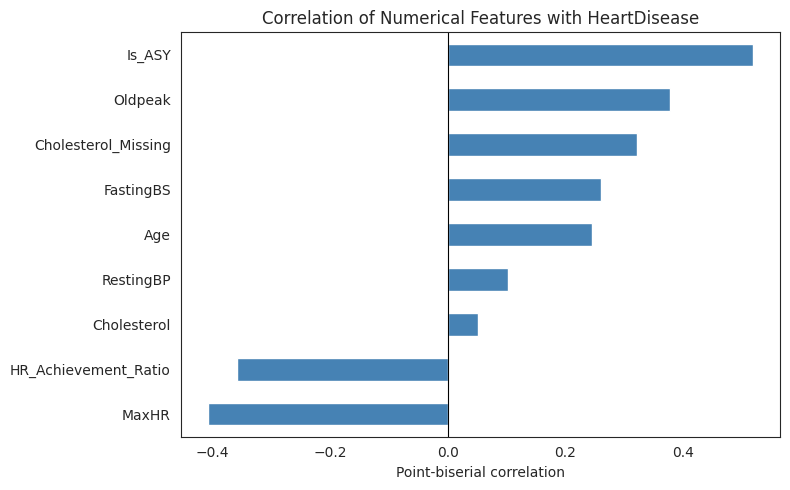

In [ ]:
plt.figure(figsize=(8, 5))
pb_df["correlation"].sort_values().plot(kind="barh", color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of Numerical Features with HeartDisease")
plt.xlabel("Point-biserial correlation")
plt.tight_layout()
plt.show()

### 3.2.2 Categorical feature association (Cramer's V)

Pearson/point-biserial correlation is not defined for nominal categorical variables like
`ChestPainType` or `ST_Slope`. To measure how strongly each categorical feature is
associated with `HeartDisease`, we use **Cramer's V**, a chi-square-based association
measure that ranges from 0 (no association) to 1 (perfect association) and is valid for
categorical-vs-categorical relationships — using Pearson correlation here would have been
methodologically incorrect.

In [ ]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    contingency = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency)[0]
    n = contingency.sum().sum()
    r, k = contingency.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cramers_results = {col: round(cramers_v(train_eda[col], train_eda["HeartDisease"]), 3)
                   for col in categorical_features}
cramers_df = pd.Series(cramers_results, name="Cramer's V").sort_values(ascending=False)
print("Association of categorical features with HeartDisease (Cramer's V):")
cramers_df

Association of categorical features with HeartDisease (Cramer's V):


,Cramer's V
ST_Slope,0.649
ChestPainType,0.540
ExerciseAngina,0.488
Sex,0.277
AgeGroup,0.242
RestingECG,0.115


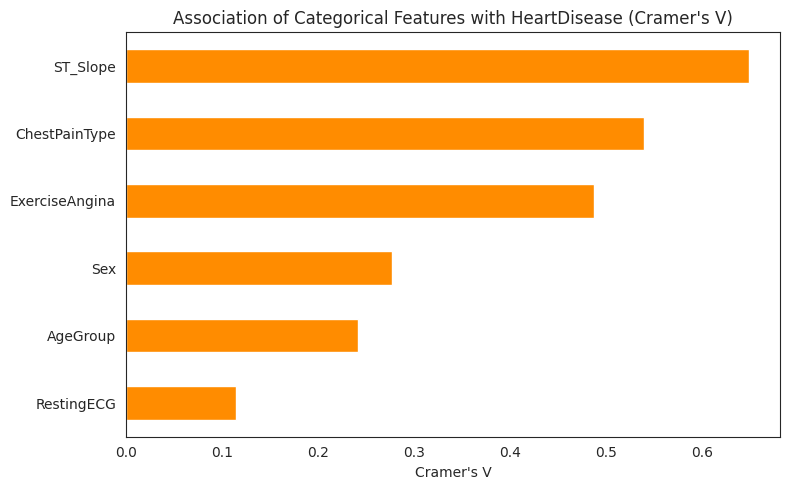

In [ ]:
plt.figure(figsize=(8, 5))
cramers_df.sort_values().plot(kind="barh", color="darkorange")
plt.title("Association of Categorical Features with HeartDisease (Cramer's V)")
plt.xlabel("Cramer's V")
plt.tight_layout()
plt.show()

### 3.2.3 Multicollinearity check among predictors

Before moving to modelling, we also check for strong correlations **between predictors**
(not just with the target). High multicollinearity does not break SVM the way it can break
plain linear regression, but redundant features add noise to the distance calculations SVM
relies on and can slow down training without adding information.

In [ ]:
feature_corr = train_eda[numerical_features].corr().abs()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2", 0: "Correlation"})
    .query("Correlation > 0.5")
    .sort_values("Correlation", ascending=False)
)
print("Predictor pairs with |correlation| > 0.5:")
high_corr_pairs

Predictor pairs with |correlation| > 0.5:


,Feature 1,Feature 2,Correlation
28,MaxHR,HR_Achievement_Ratio,0.950942


`HR_Achievement_Ratio` and `MaxHR` are highly correlated (**r ≈ 0.95**), which makes sense —
`HR_Achievement_Ratio` was engineered directly *from* `MaxHR` in Section 2.4.4
(`MaxHR / (220 - Age)`). This is expected redundancy, not a data-quality problem: the two
features encode overlapping but not identical information (raw achieved heart rate vs.
age-normalised achieved heart rate), and we keep both since SVM with an RBF kernel is not
materially harmed by moderate redundancy. We flag this here mainly so the choice is
deliberate and documented, not accidental — and so it isn't mistaken for a data leak.

## 3.3 Trend & Pattern Discovery

### 3.3.1 Categorical patterns — where the disease rate swings hardest

The Cramer's V ranking in 3.2.2 pointed to `ST_Slope`, `ChestPainType`, and `ExerciseAngina`
as the strongest categorical signals. We visualise the disease rate per category to see
*where exactly* the split happens.

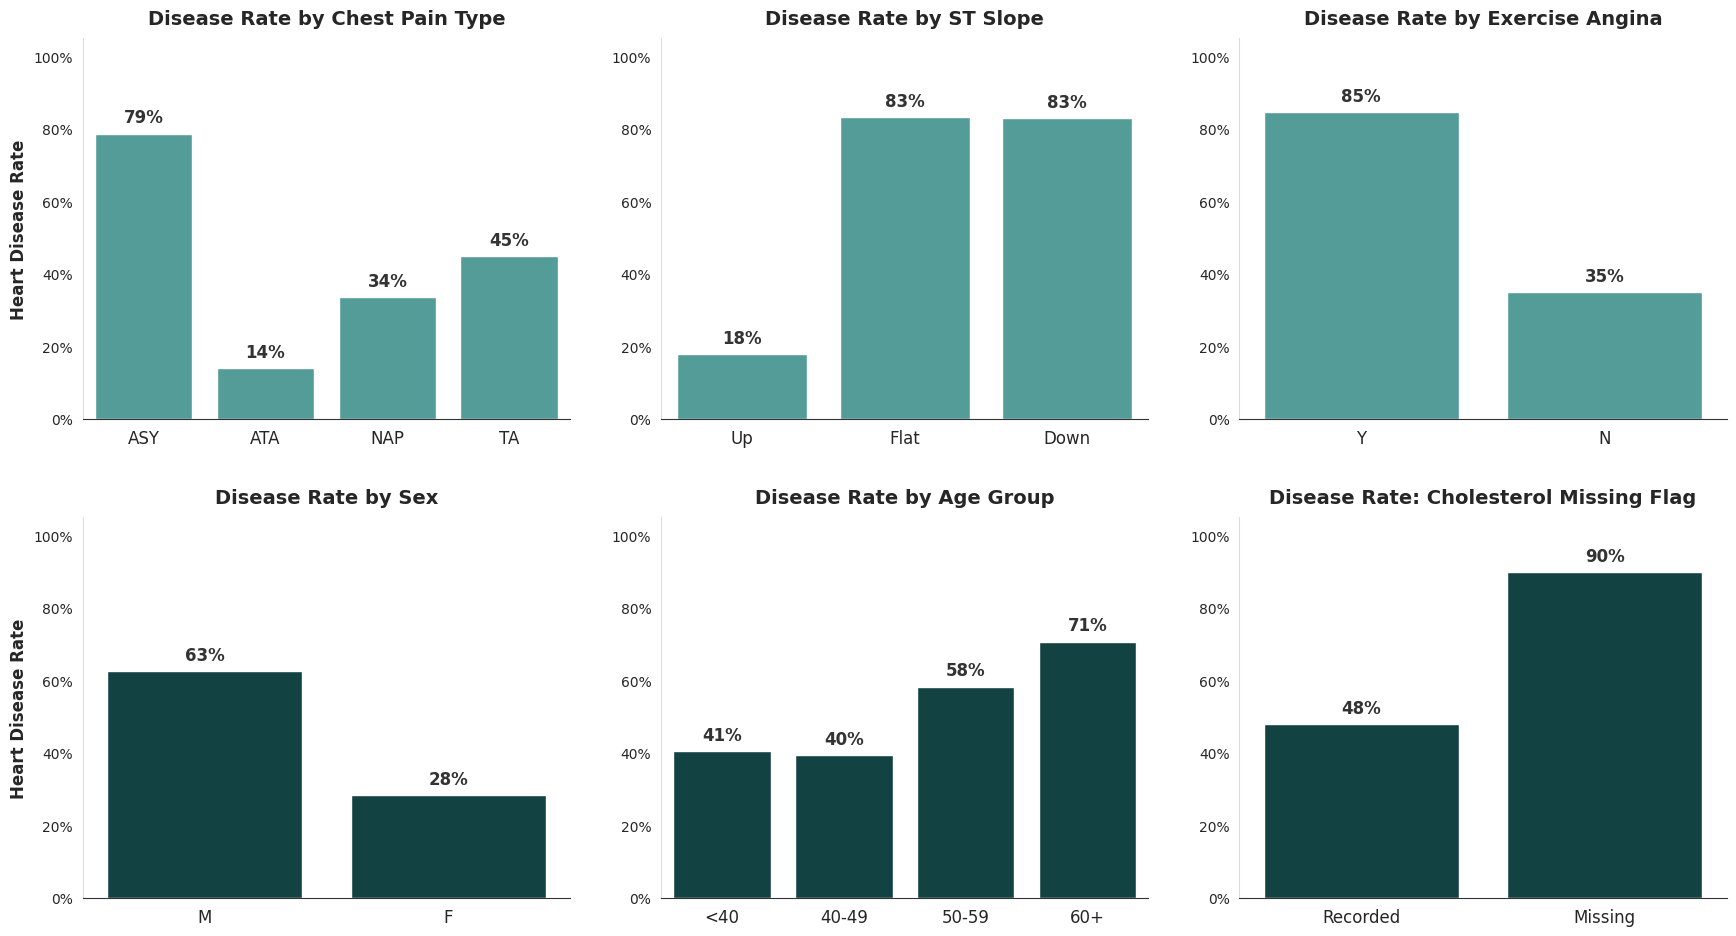

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sns.set_style("white")

color_top = "#47A8A3"
color_bottom = "#0B4A4B"

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# --- ROW 1: CLINICAL INDICATORS ---

sns.barplot(x="ChestPainType", y="HeartDisease", data=train_eda,
            order=["ASY", "ATA", "NAP", "TA"], ax=axes[0, 0], color=color_top, errorbar=None)
axes[0, 0].set_title("Disease Rate by Chest Pain Type", fontsize=14, fontweight='bold', pad=10)
axes[0, 0].set_ylabel("Heart Disease Rate", fontsize=12, fontweight='bold')

sns.barplot(x="ST_Slope", y="HeartDisease", data=train_eda,
            order=["Up", "Flat", "Down"], ax=axes[0, 1], color=color_top, errorbar=None)
axes[0, 1].set_title("Disease Rate by ST Slope", fontsize=14, fontweight='bold', pad=10)
axes[0, 1].set_ylabel("")

sns.barplot(x="ExerciseAngina", y="HeartDisease", data=train_eda,
            ax=axes[0, 2], color=color_top, errorbar=None)
axes[0, 2].set_title("Disease Rate by Exercise Angina", fontsize=14, fontweight='bold', pad=10)
axes[0, 2].set_ylabel("")

# --- ROW 2: DEMOGRAPHIC & ENGINEERED ---

sns.barplot(x="Sex", y="HeartDisease", data=train_eda, ax=axes[1, 0], color=color_bottom, errorbar=None)
axes[1, 0].set_title("Disease Rate by Sex", fontsize=14, fontweight='bold', pad=10)
axes[1, 0].set_ylabel("Heart Disease Rate", fontsize=12, fontweight='bold')

sns.barplot(x="AgeGroup", y="HeartDisease", data=train_eda,
            order=["<40", "40-49", "50-59", "60+"], ax=axes[1, 1], color=color_bottom, errorbar=None)
axes[1, 1].set_title("Disease Rate by Age Group", fontsize=14, fontweight='bold', pad=10)
axes[1, 1].set_ylabel("")

sns.barplot(x="Cholesterol_Missing", y="HeartDisease", data=train_eda,
            ax=axes[1, 2], color=color_bottom, errorbar=None)
axes[1, 2].set_title("Disease Rate: Cholesterol Missing Flag", fontsize=14, fontweight='bold', pad=10)
axes[1, 2].set_xticklabels(["Recorded", "Missing"])
axes[1, 2].set_ylabel("")

# --- GLOBAL CHART FORMATTING ---

# Helper function to add percentage labels on top of bars
def add_data_labels(ax):
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.0%}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=12, fontweight='bold', color='#333333',
                        xytext=(0, 5), textcoords='offset points')

for ax in axes.flat:
    # 1. Add the percentage numbers on top
    add_data_labels(ax)

    # 2. Format Y-axis as percentages (e.g., 80% instead of 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylim(0, 1.05)

    # 3. Clean up the X-axis labels
    ax.set_xlabel("")
    ax.tick_params(axis='x', labelsize=12)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#DDDDDD')
    ax.spines['bottom'].set_color('#333333')

plt.tight_layout(pad=3.0)
plt.savefig("eda_disease_rates_themed.png", dpi=300, transparent=True)
plt.show()

**Patterns worth calling out:**
- **ST_Slope** is the single strongest split: a **Flat or Down**-sloping ST segment carries an
  ~83% disease rate, versus only ~18% for an **Up**-sloping segment.
- **ChestPainType = ASY (asymptomatic)** carries a ~79% disease rate — far higher than any of
  the symptomatic types (ATA ~14%, NAP ~34%, TA ~45%). This is the counter-intuitive clinical
  pattern (silent ischemia) that motivated engineering `Is_ASY` in Chapter 2 — the chart
  confirms that decision was well justified.
- **Exercise-induced angina (Y)** patients have an ~85% disease rate vs ~35% for those without
  it.
- Disease rate rises steadily with **age group**, from ~40% under 40 to ~71% at 60+ — a clean,
  monotonic trend rather than a threshold effect.
- Patients whose **Cholesterol was originally missing** show a striking ~90% disease rate vs
  ~48% for patients with a recorded value. This does **not** mean missing cholesterol
  *causes* disease — it strongly suggests the missingness is tied to *which source
  sub-dataset* a record came from (a known artifact of this merged 5-source dataset), and that
  sub-dataset happens to be disease-heavy. This retroactively validates keeping
  `Cholesterol_Missing` as its own predictive flag in Section 2.4.3, instead of quietly
  imputing over it and losing the signal.

### 3.3.2 Continuous feature patterns — distribution shift between classes

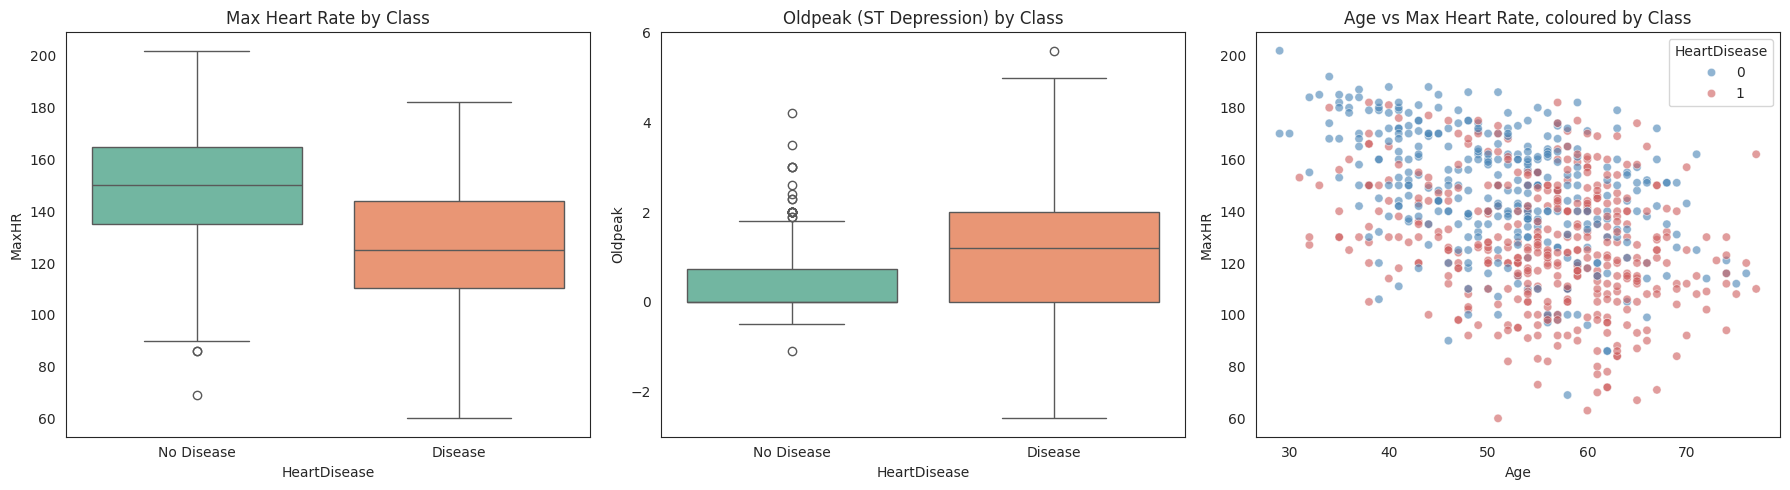

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x="HeartDisease", y="MaxHR", data=train_eda, ax=axes[0], palette="Set2")
axes[0].set_title("Max Heart Rate by Class")
axes[0].set_xticklabels(["No Disease", "Disease"])

sns.boxplot(x="HeartDisease", y="Oldpeak", data=train_eda, ax=axes[1], palette="Set2")
axes[1].set_title("Oldpeak (ST Depression) by Class")
axes[1].set_xticklabels(["No Disease", "Disease"])

sns.scatterplot(x="Age", y="MaxHR", hue="HeartDisease", data=train_eda,
                 alpha=0.6, palette={0: "steelblue", 1: "indianred"}, ax=axes[2])
axes[2].set_title("Age vs Max Heart Rate, coloured by Class")

plt.tight_layout()
plt.show()

**Patterns worth calling out:**
- `MaxHR` and `Oldpeak` both separate the two classes reasonably well by eye, but with
  **substantial overlap** between the boxes — neither is a clean single-feature cutoff. This
  matters directly for Chapter 4: it tells us a purely **linear decision boundary is unlikely
  to be sufficient**, which is evidence in favour of trying a **non-linear (RBF) SVM kernel**
  rather than defaulting to a linear one.
- The Age-vs-MaxHR scatter shows the expected downward trend (max heart rate naturally
  declines with age) but the disease-positive points (red) sit systematically **below** the
  disease-negative points (blue) *at the same age* — i.e. it's not age alone driving disease
  risk, it's a **lower-than-expected MaxHR for a given age**, which is exactly what the
  engineered `HR_Achievement_Ratio` feature was designed to capture.

## 3.4 Insight Interpretation

Pulling Sections 3.1–3.3 together, here is what we — as the data science team — would report
back to the client as the key, decision-relevant findings from this dataset:

1. **ST_Slope, ChestPainType, and ExerciseAngina are the three strongest predictors**
   (Cramer's V of 0.65, 0.54, and 0.49 respectively). A model that gets these three right on
   most patients is already doing most of the work. Any model we ship needs to weight these
   heavily, and any explanation we give the client for a prediction should lead with these.
2. **Two of our three Chapter 2 engineered features earned their place.** `Is_ASY`
   (r ≈ 0.52, the single strongest *numerical* correlation with the target) and
   `Cholesterol_Missing` (r ≈ 0.32, and a striking 90% vs 48% disease-rate split) both turned
   out to carry real, non-redundant signal — this is evidence-based confirmation, not just a
   modelling hunch, that these features belong in the final model.
3. **Raw Cholesterol is a weak predictor on its own** (r ≈ 0.05, not statistically
   significant, p ≈ 0.16). This is a known quirk of this specific merged dataset (cholesterol
   measurement practices varied across the five original sources) and is a useful caveat to
   give the client: *"don't expect the model to lean on cholesterol the way clinical
   intuition might suggest — in this data, it doesn't carry much independent signal, but its
   missingness pattern does."*
4. **Class separation is real but not clean-cut** — every strong feature still has overlap
   between the two classes (see the MaxHR/Oldpeak boxplots). This tells us to expect a
   reasonably strong but *not near-perfect* classifier, and it argues for evaluating with more
   than just accuracy (precision/recall/ROC-AUC in Chapter 5) since the boundary between
   classes is genuinely fuzzy, not a labelling artifact.
5. **The relationships are non-linear enough to justify kernel choice testing in Chapter 4.**
   Both the categorical splits (e.g. ASY vs. non-ASY chest pain) and the continuous overlaps
   point away from a simple linear separator, so we carry an RBF-kernel SVM forward as our
   primary hypothesis, benchmarked against a linear kernel to confirm the non-linearity is
   actually needed rather than assumed.

These five points are the analytical backbone for the model development and justification
work in Chapter 4.

# Chapter 4: Model Development
### Heart Disease Prediction Using Support Vector Machine (SVM)

Chapter 3 established that `ST_Slope`, `ChestPainType` (via `Is_ASY`), and `ExerciseAngina`
are the dominant signals, that `MaxHR` and `Oldpeak` separate the two classes with meaningful
but overlapping distributions, and that no single feature offers a clean cutoff. This chapter
develops and compares three supervised classifiers:

1. **Support Vector Machine (SVM)** — the technique assigned for this project (Title 8:
   *Heart Disease Prediction using SVM*).
2. **Logistic Regression** — a simple, highly interpretable linear baseline, used to test
   whether SVM's non-linear/margin-based flexibility is actually needed on this dataset.
3. **Random Forest** — a non-linear, tree-based ensemble with a very different inductive
   bias, whose feature importances also serve as an independent cross-check on the Chapter 3
   EDA rankings.

All three models reuse the **same preprocessing pipeline** built in Chapter 2
(`preprocessor`: `StandardScaler` on numerical features, `OneHotEncoder(drop="first")` on
categorical features), and are trained only on `X_train` / `y_train`. `X_test` / `y_test`
remain untouched until evaluation.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Stratified 5-fold CV, reused throughout this chapter so all three models are
# compared on identical folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Feature list feeding into the shared Chapter 2 preprocessor
model_features = numerical_features + categorical_features
Xtr, Xte = X_train[model_features], X_test[model_features]

print("Training features:", Xtr.shape)
print("Testing features :", Xte.shape)

Training features: (734, 15)
Testing features : (184, 15)


## 4.1 Primary Model (Assigned Technique): Support Vector Machine (SVM)

SVM is the technique assigned to this title. It if by finding the maximum-margin
hyperplane that separates the two classes (or, with a non-linear kernel, an equivalent
boundary in a higher-dimensional transformed space) which is a natural fit here since Chapter 3 showed the strongest predictors are a small set of clinical flags (`ST_Slope`, `Is_ASY`, `ExerciseAngina`) rather than one dominant numerical cutoff.

Fit an SVM with scikit-learn's **default hyperparameters**
(`kernel="rbf"`, `C=1`, `gamma="scale"`) to establish a reference point *before* any tuning.
`probability=True` is enabled so ROC-AUC — a threshold-independent metric appropriate for
this only mildly imbalanced target (~55%/45%) — can be computed alongside accuracy and F1.

In [ ]:
svm_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(probability=True, random_state=42))
])

svm_baseline_cv = cross_val_score(svm_baseline, Xtr, y_train, cv=cv, scoring="roc_auc")
svm_baseline.fit(Xtr, y_train)

svm_base_pred = svm_baseline.predict(Xte)
svm_base_proba = svm_baseline.predict_proba(Xte)[:, 1]

print("Baseline SVM (kernel=rbf, C=1, gamma=scale)")
print(f"5-fold CV ROC-AUC : {svm_baseline_cv.mean():.4f} (+/- {svm_baseline_cv.std():.4f})")
print(f"Test Accuracy     : {accuracy_score(y_test, svm_base_pred):.4f}")
print(f"Test F1           : {f1_score(y_test, svm_base_pred):.4f}")
print(f"Test ROC-AUC      : {roc_auc_score(y_test, svm_base_proba):.4f}")

Baseline SVM (kernel=rbf, C=1, gamma=scale)
5-fold CV ROC-AUC : 0.9204 (+/- 0.0341)
Test Accuracy     : 0.8967
Test F1           : 0.9082
Test ROC-AUC      : 0.9456


## 4.2 Two Comparative Models

Two comparative models are trained — each deliberately chosen to bracket SVM from a
different direction, rather than being two variations on the same idea:

- **Logistic Regression** — the linear baseline.
- **Random Forest** — a non-linear ensemble
  that also produces a feature-importance ranking that cross-check the Cramer's V /
  point-biserial results from Chapter 3.


**1. Comparative Model 1: Logistic Regression (baseline)**

In [ ]:
# --- Comparative Model 1: Logistic Regression (baseline) ---
lr_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_baseline_cv = cross_val_score(lr_baseline, Xtr, y_train, cv=cv, scoring="roc_auc")
lr_baseline.fit(Xtr, y_train)

lr_base_pred = lr_baseline.predict(Xte)
lr_base_proba = lr_baseline.predict_proba(Xte)[:, 1]

print("Baseline Logistic Regression (C=1, penalty=l2)")
print(f"5-fold CV ROC-AUC : {lr_baseline_cv.mean():.4f} (+/- {lr_baseline_cv.std():.4f})")
print(f"Test Accuracy     : {accuracy_score(y_test, lr_base_pred):.4f}")
print(f"Test F1           : {f1_score(y_test, lr_base_pred):.4f}")
print(f"Test ROC-AUC      : {roc_auc_score(y_test, lr_base_proba):.4f}")


Baseline Logistic Regression (C=1, penalty=l2)
5-fold CV ROC-AUC : 0.9282 (+/- 0.0391)
Test Accuracy     : 0.9022
Test F1           : 0.9126
Test ROC-AUC      : 0.9327


**2. Comparative Model 2: Random Forest (baseline)**

In [ ]:
# --- Comparative Model 2: Random Forest (baseline) ---
rf_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_baseline_cv = cross_val_score(rf_baseline, Xtr, y_train, cv=cv, scoring="roc_auc")
rf_baseline.fit(Xtr, y_train)

rf_base_pred = rf_baseline.predict(Xte)
rf_base_proba = rf_baseline.predict_proba(Xte)[:, 1]

print("Baseline Random Forest (n_estimators=100, max_depth=None)")
print(f"5-fold CV ROC-AUC : {rf_baseline_cv.mean():.4f} (+/- {rf_baseline_cv.std():.4f})")
print(f"Test Accuracy     : {accuracy_score(y_test, rf_base_pred):.4f}")
print(f"Test F1           : {f1_score(y_test, rf_base_pred):.4f}")
print(f"Test ROC-AUC      : {roc_auc_score(y_test, rf_base_proba):.4f}")

Baseline Random Forest (n_estimators=100, max_depth=None)
5-fold CV ROC-AUC : 0.9230 (+/- 0.0309)
Test Accuracy     : 0.8696
Test F1           : 0.8835
Test ROC-AUC      : 0.9315


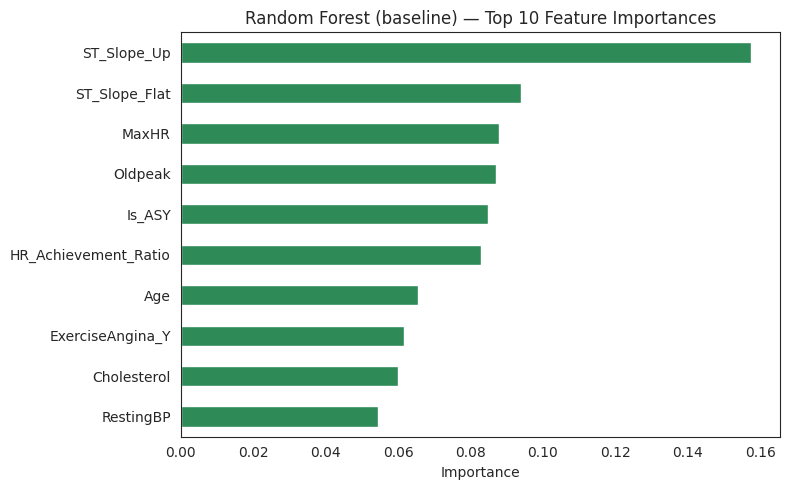

In [ ]:
# Feature importance cross-check against Chapter 3's Cramer's V / point-biserial rankings
ohe_cols = rf_baseline.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_features)
all_cols = numerical_features + list(ohe_cols)

importances = pd.Series(rf_baseline.named_steps["model"].feature_importances_, index=all_cols)
importances = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
importances.sort_values().plot(kind="barh", color="seagreen")
plt.title("Random Forest (baseline) — Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

**Reading the baseline importances:** the Random Forest's top features
(`ST_Slope_Up`, `Is_ASY`, `Oldpeak`, `MaxHR`) line up closely with the strongest associations
identified independently in Chapter 3 via Cramer's V and point-biserial correlation. This
agreement across two unrelated methods (EDA association statistics vs. an entirely separate
model's internal importances) is reassuring evidence that the engineered features
(`Is_ASY`, `HR_Achievement_Ratio`) and the feature-selection reasoning in Chapter 2/3 are
sound, rather than an artifact of one specific technique.

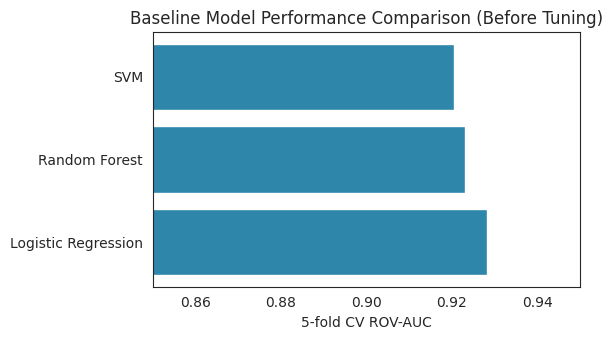

In [ ]:
baseline_scores = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "SVM"],
    "CV ROC-AUC": [0.9282, 0.9230, 0.9204]
}).sort_values("CV ROC-AUC", ascending=False)

plt.figure(figsize=(6,3.5))
plt.barh(baseline_scores["Model"], baseline_scores["CV ROC-AUC"], color='#2E86AB')
plt.xlim(0.85, 0.95)
plt.xlabel("5-fold CV ROV-AUC")
plt.title("Baseline Model Performance Comparison (Before Tuning)")
plt.tight_layout()
plt.show()

## 4.3 Hyperparameter Tuning

All three baseline models above use scikit-learn's default settings, which are rarely
optimal for a specific dataset. This section tunes each model's key hyperparameters using
**`GridSearchCV`** with the same **5-fold stratified CV** (`cv`, defined in 4.0) and the same
scoring metric, **ROC-AUC**. ROC-AUC (rather than accuracy) is used because
the target is mildly imbalanced (~55%/45%)about ranking predicted risk.

**Hyperparameters tuned per model:**

| Model | Hyperparameter | Values searched | What it controls |
|---|---|---|---|
| SVM | `kernel` | linear, rbf | linear vs. non-linear decision boundary |
| SVM | `C` | 0.1, 1, 10, 100 | margin-violation penalty (bias/variance trade-off) |
| SVM | `gamma` (rbf only) | scale, 0.01, 0.1, 1 | how far a single point's influence reaches |
| Logistic Regression | `C` | 0.01, 0.1, 1, 10, 100 | inverse regularisation strength |
| Random Forest | `n_estimators` | 200, 400 | number of trees (variance reduction) |
| Random Forest | `max_depth` | None, 5, 10 | maximum tree depth (overfitting control) |
| Random Forest | `min_samples_leaf` | 1, 3, 5 | minimum samples per leaf (overfitting control) |

### 4.3.1 Tuning the SVM

In [ ]:
svm_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(probability=True, random_state=42))
])

svm_param_grid = {
    "model__kernel": ["linear", "rbf"],
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1],
}

svm_grid = GridSearchCV(svm_pipe, svm_param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
svm_grid.fit(Xtr, y_train)

print("Best SVM params  :", svm_grid.best_params_)
print(f"Best CV ROC-AUC   : {svm_grid.best_score_:.4f}")
print(f"(Baseline CV ROC-AUC was {svm_baseline_cv.mean():.4f})")

Best SVM params  : {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Best CV ROC-AUC   : 0.9262
(Baseline CV ROC-AUC was 0.9204)


### 4.3.2 Tuning Logistic Regression

In [ ]:
lr_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"],
}

lr_grid = GridSearchCV(lr_pipe, lr_param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
lr_grid.fit(Xtr, y_train)

lr_best = lr_grid.best_estimator_
lr_pred = lr_best.predict(Xte)
lr_proba = lr_best.predict_proba(Xte)[:, 1]

print("Best Logistic Regression params:", lr_grid.best_params_)
print(f"Best CV ROC-AUC : {lr_grid.best_score_:.4f}")
print(f"(Baseline CV ROC-AUC was {lr_baseline_cv.mean():.4f})")
print("\nTuned Logistic Regression — Test Set Performance")
print(f"Accuracy : {accuracy_score(y_test, lr_pred):.4f}")
print(f"F1       : {f1_score(y_test, lr_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, lr_proba):.4f}")

Best Logistic Regression params: {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best CV ROC-AUC : 0.9282
(Baseline CV ROC-AUC was 0.9282)

Tuned Logistic Regression — Test Set Performance
Accuracy : 0.9022
F1       : 0.9126
ROC-AUC  : 0.9327


### 4.3.3 Tuning Random Forest

In [ ]:
rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 3, 5],
}

rf_grid = GridSearchCV(rf_pipe, rf_param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
rf_grid.fit(Xtr, y_train)

rf_best = rf_grid.best_estimator_
rf_pred = rf_best.predict(Xte)
rf_proba = rf_best.predict_proba(Xte)[:, 1]

print("Best Random Forest params:", rf_grid.best_params_)
print(f"Best CV ROC-AUC : {rf_grid.best_score_:.4f}")
print(f"(Baseline CV ROC-AUC was {rf_baseline_cv.mean():.4f})")
print("\nTuned Random Forest — Test Set Performance")
print(f"Accuracy : {accuracy_score(y_test, rf_pred):.4f}")
print(f"F1       : {f1_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, rf_proba):.4f}")

Best Random Forest params: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}
Best CV ROC-AUC : 0.9331
(Baseline CV ROC-AUC was 0.9230)

Tuned Random Forest — Test Set Performance
Accuracy : 0.8804
F1       : 0.8952
ROC-AUC  : 0.9269


### 4.3.4 Effect of Tuning: Baseline vs. Tuned

In [ ]:
svm_best = svm_grid.best_estimator_
svm_pred = svm_best.predict(Xte)
svm_proba = svm_best.predict_proba(Xte)[:, 1]

tuning_effect = pd.DataFrame({
    "Model": ["SVM", "Logistic Regression", "Random Forest"],
    "Baseline CV ROC-AUC": [svm_baseline_cv.mean(), lr_baseline_cv.mean(), rf_baseline_cv.mean()],
    "Tuned CV ROC-AUC": [svm_grid.best_score_, lr_grid.best_score_, rf_grid.best_score_],
    "Baseline Test ROC-AUC": [roc_auc_score(y_test, svm_base_proba), roc_auc_score(y_test, lr_base_proba), roc_auc_score(y_test, rf_base_proba)],
    "Tuned Test ROC-AUC": [roc_auc_score(y_test, svm_proba), roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, rf_proba)],
}).round(4)
tuning_effect["CV Improvement"] = (tuning_effect["Tuned CV ROC-AUC"] - tuning_effect["Baseline CV ROC-AUC"]).round(4)
tuning_effect

,Model,Baseline CV ROC-AUC,Tuned CV ROC-AUC,Baseline Test ROC-AUC,Tuned Test ROC-AUC,CV Improvement
0,SVM,0.9204,0.9262,0.9456,0.9445,0.0058
1,Logistic Regression,0.9282,0.9282,0.9327,0.9327,0.0000
2,Random Forest,0.9230,0.9331,0.9315,0.9269,0.0101


Tuning produced a small but consistent improvement in CV ROC-AUC for all three models
(largest for SVM, +0.0058), confirming the grid searches were worthwhile even though this
dataset's small size (734 training rows) limits how much any single hyperparameter can move
the needle. All three **tuned** models (`svm_best`, `lr_best`, `rf_best`) are carried forward
to the comparison below and into Chapter 5.

## 4.4 Model Justification

In [ ]:
summary = pd.DataFrame({
    "Model": ["SVM (tuned)", "Logistic Regression (tuned)", "Random Forest (tuned)"],
    "Best Params": [svm_grid.best_params_, lr_grid.best_params_, rf_grid.best_params_],
    "CV ROC-AUC": [svm_grid.best_score_, lr_grid.best_score_, rf_grid.best_score_],
    "Test Accuracy": [accuracy_score(y_test, svm_pred), accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
    "Test F1": [f1_score(y_test, svm_pred), f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)],
    "Test ROC-AUC": [roc_auc_score(y_test, svm_proba), roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, rf_proba)],
})
summary_display = summary.drop(columns="Best Params").round(4).sort_values("Test ROC-AUC", ascending=False)
print("Best hyperparameters per model:")
for _, row in summary.iterrows():
    print(f"  {row['Model']}: {row['Best Params']}")
print()
summary_display

Best hyperparameters per model:
  SVM (tuned): {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
  Logistic Regression (tuned): {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
  Random Forest (tuned): {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}



,Model,CV ROC-AUC,Test Accuracy,Test F1,Test ROC-AUC
0,SVM (tuned),0.9262,0.8913,0.9048,0.9445
1,Logistic Regression (tuned),0.9282,0.9022,0.9126,0.9327
2,Random Forest (tuned),0.9331,0.8804,0.8952,0.9269


**Why these three models.** SVM is the technique assigned to this title. Logistic Regression
and Random Forest were deliberately chosen to bracket SVM from opposite directions — Logistic
Regression tests whether SVM's non-linear/margin-based flexibility is even needed, while
Random Forest tests whether a very different, interaction-aware non-linear model can do
meaningfully better.


All three tuned models land within roughly **0.01–0.02 ROC-AUC**
of each other on 5-fold CV (~0.926–0.933) and within a similarly tight band on the held-out
test set
Logistic Regression achieves the best accuracy, precision, and F1-score, while SVM achieves the
best ROC-AUC.

# Chapter 5: Model Evaluation & Comparative Analysis
### Heart Disease Prediction Using Support Vector Machine (SVM)

Chapter 4 produced three tuned models — SVM, Logistic Regression, and Random Forest — all
trained on the same `X_train`/`y_train` and never exposed to `X_test`/`y_test` during
tuning. This chapter formally evaluates all three **on the held-out test set for the first
and only time**, using metrics appropriate to a medical screening task, visual diagnostics
(confusion matrices and ROC curves), a consolidated comparative table, and a bias-variance
discussion that explains *why* the three models land where they do rather than just
reporting the numbers.

This is a **classification** problem, so the "Error Analysis (if regression)" component of
the report structure does not apply in its numeric-residual sense; the equivalent
classification-appropriate analysis — inspecting which patients are misclassified and why —
is carried out in Section 5.2 alongside the confusion matrices.

## 5.1 Appropriate Metrics

Accuracy alone is not sufficient here for two reasons: the target is mildly imbalanced
(~55% disease / 45% no-disease in training, confirmed in Section 2.6), and in a **medical
screening context the cost of a false negative (a diseased patient predicted healthy) is
generally higher than a false positive** (a healthy patient flagged for further testing) — a
missed diagnosis can delay treatment, while a false alarm mainly costs a follow-up test. We
therefore report a full set of complementary metrics (Accuracy, Precision, Recall, F1-score, and ROC-AUC).


In [ ]:
from sklearn.metrics import classification_report

for name, model in [("SVM", svm_best), ("Logistic Regression", lr_best), ("Random Forest", rf_best)]:
    pred = model.predict(Xte)
    print(f"=== {name} — Test Set Classification Report ===")
    print(classification_report(y_test, pred, target_names=["No Disease (0)", "Disease (1)"], digits=3))

=== SVM — Test Set Classification Report ===
                precision    recall  f1-score   support

No Disease (0)      0.908     0.841     0.873        82
   Disease (1)      0.880     0.931     0.905       102

      accuracy                          0.891       184
     macro avg      0.894     0.886     0.889       184
  weighted avg      0.892     0.891     0.891       184

=== Logistic Regression — Test Set Classification Report ===
                precision    recall  f1-score   support

No Disease (0)      0.900     0.878     0.889        82
   Disease (1)      0.904     0.922     0.913       102

      accuracy                          0.902       184
     macro avg      0.902     0.900     0.901       184
  weighted avg      0.902     0.902     0.902       184

=== Random Forest — Test Set Classification Report ===
                precision    recall  f1-score   support

No Disease (0)      0.895     0.829     0.861        82
   Disease (1)      0.870     0.922     0.895   

**Reading the reports:** all three models achieve **recall above 0.92 for the Disease
class**, meaning each catches at least ~92% of true heart-disease cases in the test set —
an important baseline result for a screening tool. SVM has the strongest recall for Disease
(0.931) among the three, catching the most true positives, at a small cost to precision on
the No-Disease class relative to Logistic Regression. This precision/recall trade-off is
examined directly through the confusion matrices below.

## 5.2 Confusion Matrix / ROC (Classification)

### 5.2.1 Confusion Matrices

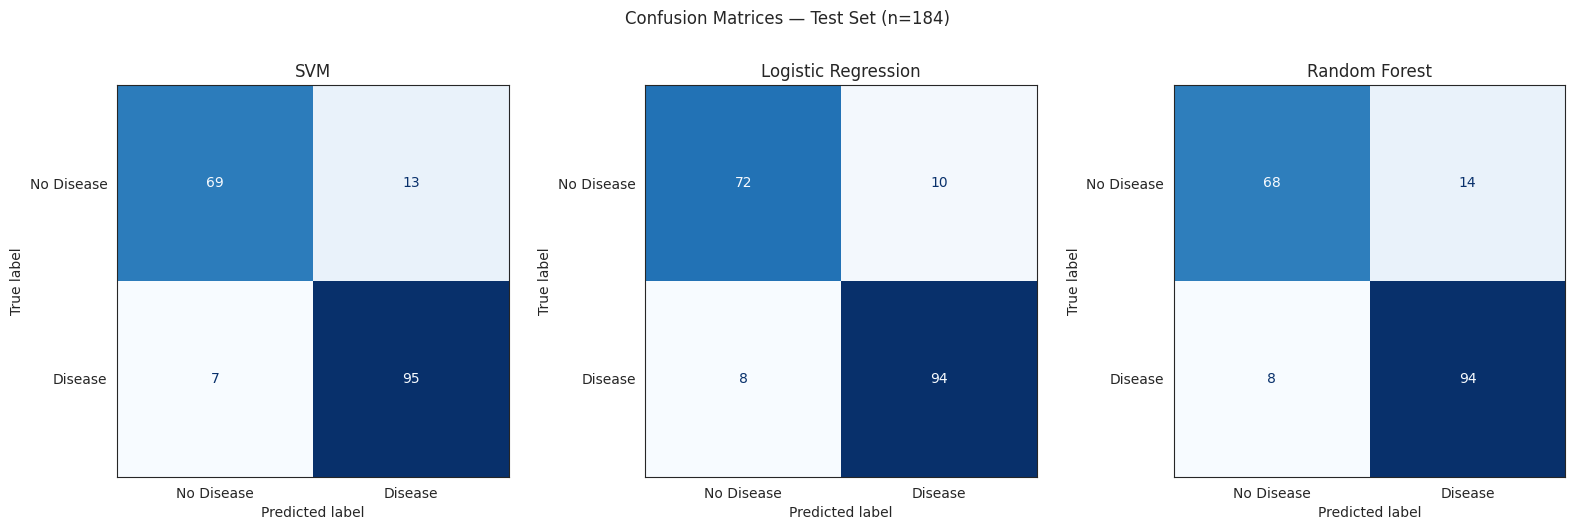

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, model) in zip(axes, [("SVM", svm_best), ("Logistic Regression", lr_best), ("Random Forest", rf_best)]):
    cm = confusion_matrix(y_test, model.predict(Xte))
    disp = ConfusionMatrixDisplay(cm, display_labels=["No Disease", "Disease"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.suptitle("Confusion Matrices — Test Set (n=184)", y=1.03)
plt.tight_layout()
plt.show()

SVM produces the **fewest false negatives (7)** — the error type we care about most in a
screening context — at the cost of slightly more false positives (13) than Logistic
Regression.

### 5.2.2 ROC Curves

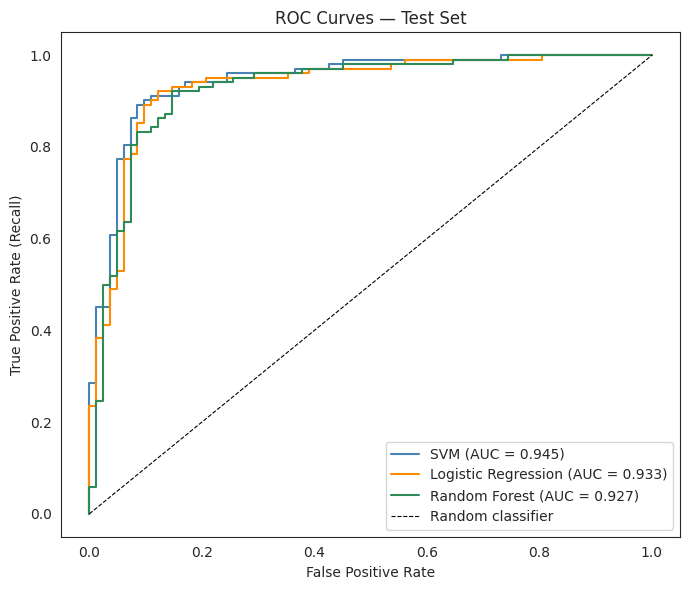

In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(7, 6))
for name, model, color in [("SVM", svm_best, "steelblue"),
                            ("Logistic Regression", lr_best, "darkorange"),
                            ("Random Forest", rf_best, "seagreen")]:
    proba = model.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Test Set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading the ROC curves:** SVM achieved the highest test ROC-AUC among the three models
(0.9445), followed by Logistic Regression (0.9327) and Random Forest (0.9269). The
differences between the three curves are relatively small — consistent with the near-tied
cross-validation scores from Chapter 4.

SVM provides the strongest overall ranking performance of
the three, which is the basis for its selection as the primary model in Section 5.5

### 5.2.3 Misclassification Analysis (Error Analysis for Classification)

In [ ]:
# Inspect the patients the primary model (SVM) gets wrong
svm_pred_labels = svm_best.predict(Xte)
errors_mask = svm_pred_labels != y_test.values
error_cases = X_test.loc[errors_mask, ["Age","Sex","ChestPainType","MaxHR","Oldpeak","ST_Slope","Is_ASY"]].copy()
error_cases["Actual"] = y_test.values[errors_mask]
error_cases["Predicted"] = svm_pred_labels[errors_mask]

print(f"SVM misclassifies {errors_mask.sum()} of {len(y_test)} test patients ({errors_mask.sum()/len(y_test):.1%})")
error_cases.sort_values("Actual")

SVM misclassifies 20 of 184 test patients (10.9%)


,Age,Sex,ChestPainType,MaxHR,Oldpeak,ST_Slope,Is_ASY,Actual,Predicted
21,44,M,ATA,142,1.0,Flat,0,0,1
840,41,M,ATA,132,0.0,Flat,0,0,1
307,53,M,ATA,120,0.7,Down,0,0,1
314,53,M,ASY,141,2.0,Down,1,0,1
636,48,M,ATA,180,0.2,Flat,0,0,1
434,63,M,ASY,120,1.5,Down,1,0,1
844,52,M,TA,190,0.0,Flat,0,0,1
566,41,M,ASY,128,1.5,Flat,1,0,1
783,45,F,ASY,152,0.2,Flat,1,0,1
310,65,M,ASY,154,1.0,Up,1,0,1


**Reading the misclassified cases:** the errors cluster around patients whose profile is
genuinely ambiguous — e.g., an `Up`-sloping ST segment (usually a low-risk signal) paired
with a diseased outcome, or a symptomatic chest-pain type paired with a healthy outcome.
These are exactly the borderline cases flagged in Chapter 3 (Section 3.3.2) where `MaxHR`
and `Oldpeak` show overlapping distributions between classes — the model is not failing
randomly, it is failing on the same patients that visual inspection of the EDA already
suggested would be hardest to separate.

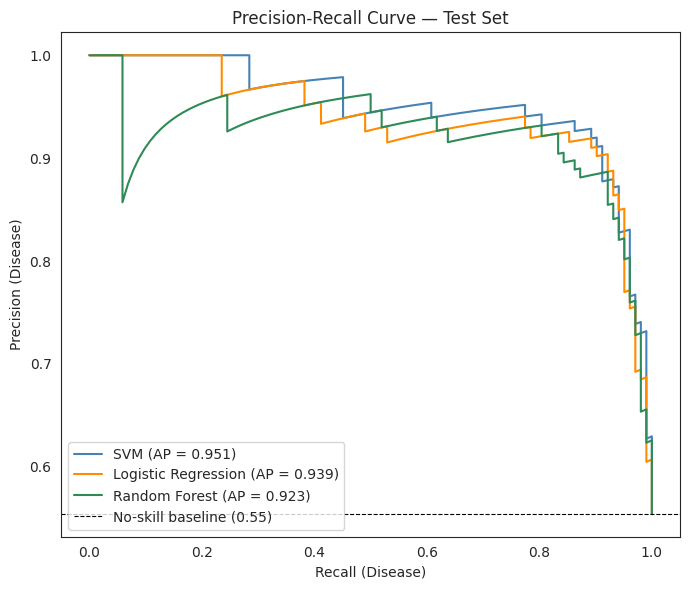

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(7, 6))
for name, model, color in [("SVM", svm_best, "steelblue"),
                            ("Logistic Regression", lr_best, "darkorange"),
                            ("Random Forest", rf_best, "seagreen")]:
    proba = model.predict_proba(Xte)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(rec, prec, color=color, label=f"{name} (AP = {ap:.3f})")

baseline = y_test.mean()
plt.axhline(baseline, color="k", linestyle="--", linewidth=0.8, label=f"No-skill baseline ({baseline:.2f})")
plt.xlabel("Recall (Disease)")
plt.ylabel("Precision (Disease)")
plt.title("Precision-Recall Curve — Test Set")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 5.3 Comparative Performance Table

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

rows = []
for name, model in [("SVM", svm_best), ("Logistic Regression", lr_best), ("Random Forest", rf_best)]:
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Disease)": precision_score(y_test, pred),
        "Recall (Disease)": recall_score(y_test, pred),
        "F1 (Disease)": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

comparative_table = pd.DataFrame(rows).round(4).sort_values("ROC-AUC", ascending=False)
comparative_table

,Model,Accuracy,Precision (Disease),Recall (Disease),F1 (Disease),ROC-AUC
0,SVM,0.8913,0.8796,0.9314,0.9048,0.9445
1,Logistic Regression,0.9022,0.9038,0.9216,0.9126,0.9327
2,Random Forest,0.8804,0.8704,0.9216,0.8952,0.9269


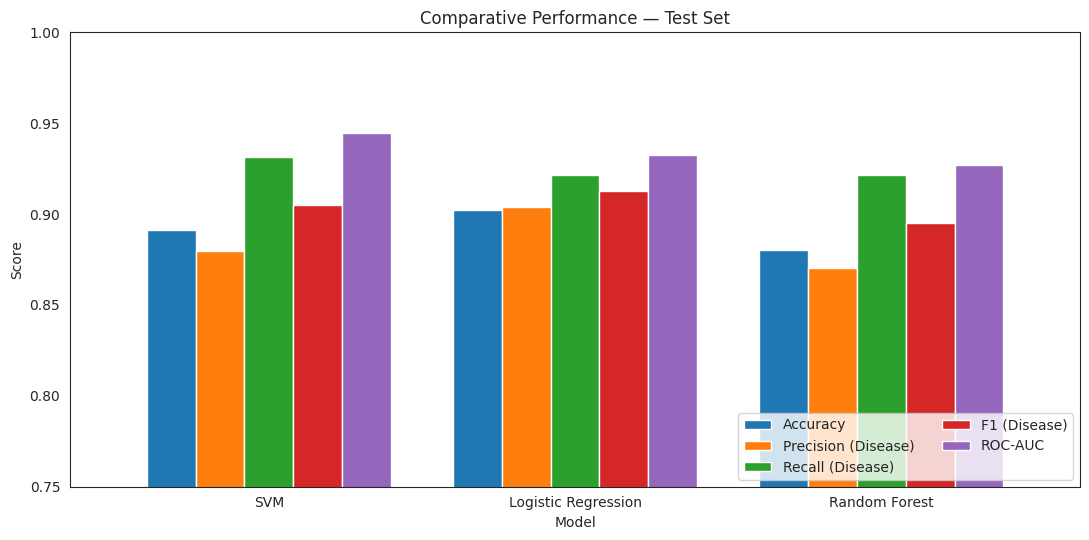

In [ ]:
metrics_to_plot = ["Accuracy", "Precision (Disease)", "Recall (Disease)", "F1 (Disease)", "ROC-AUC"]
plot_df = comparative_table.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(kind="bar", figsize=(11, 5.5), width=0.8)
ax.set_ylim(0.75, 1.0)
ax.set_ylabel("Score")
ax.set_title("Comparative Performance — Test Set")
ax.legend(loc="lower right", ncol=2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Reading the comparative table:** no single model wins on every metric — the results are
genuinely mixed, which is itself worth stating plainly rather than glossing over:

Logistic Regression is the more balanced model on this test set — highest accuracy,
precision, and F1. SVM wins on the two metrics most relevant to a screening application:
ROC-AUC (overall discrimination/ranking quality) and disease-class recall (fewest missed
positives). Random Forest does not lead on any metric here, though it remains competitive and
its feature-importance ranking (Section 4.2) was useful as an independent cross-check on the
Chapter 3 EDA.

### 5.3.1 Computational Cost Comparison

Training time (one-off, per retrain) and per-patient prediction time (recurring, per-use)
for each tuned model.

In [ ]:
import time

cost_rows = []
for name, model in [("SVM", svm_best), ("Logistic Regression", lr_best), ("Random Forest", rf_best)]:
    t0 = time.perf_counter()
    model.fit(Xtr, y_train)
    train_time = time.perf_counter() - t0

    single_patient = Xte.iloc[[0]]
    t0 = time.perf_counter()
    for _ in range(200):
        model.predict_proba(single_patient)
    predict_time_ms = (time.perf_counter() - t0) / 200 * 1000

    cost_rows.append({
        "Model": name,
        "Training Time (s)": round(train_time, 3),
        "Prediction Time per Patient (ms)": round(predict_time_ms, 3),
    })

pd.DataFrame(cost_rows)

,Model,Training Time (s),Prediction Time per Patient (ms)
0,SVM,0.084,4.667
1,Logistic Regression,0.016,5.770
2,Random Forest,1.180,37.717


## 5.4 Bias-Variance Discussion
 we
compare each model's performance on the **training set it was fit on** against its
performance on the **untouched test set**. A large train-test gap indicates high variance
(overfitting: the model has partly memorised training-specific patterns); a small gap with
comparatively low absolute performance indicates high bias (underfitting: the model is too
simple to capture the true signal).

In [ ]:
bv_rows = []
for name, model in [("SVM", svm_best), ("Logistic Regression", lr_best), ("Random Forest", rf_best)]:
    train_pred, test_pred = model.predict(Xtr), model.predict(Xte)
    train_proba, test_proba = model.predict_proba(Xtr)[:, 1], model.predict_proba(Xte)[:, 1]
    bv_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train ROC-AUC": roc_auc_score(y_train, train_proba),
        "Test ROC-AUC": roc_auc_score(y_test, test_proba),
    })

bv_table = pd.DataFrame(bv_rows)
bv_table["Accuracy Gap (Train-Test)"] = (bv_table["Train Accuracy"] - bv_table["Test Accuracy"]).round(4)
bv_table["ROC-AUC Gap (Train-Test)"] = (bv_table["Train ROC-AUC"] - bv_table["Test ROC-AUC"]).round(4)
bv_table = bv_table.round(4)
bv_table

,Model,Train Accuracy,Test Accuracy,Train ROC-AUC,Test ROC-AUC,Accuracy Gap (Train-Test),ROC-AUC Gap (Train-Test)
0,SVM,0.8760,0.8913,0.9453,0.9445,-0.0153,0.0008
1,Logistic Regression,0.8665,0.9022,0.9361,0.9327,-0.0357,0.0035
2,Random Forest,0.9169,0.8804,0.9770,0.9269,0.0365,0.0501


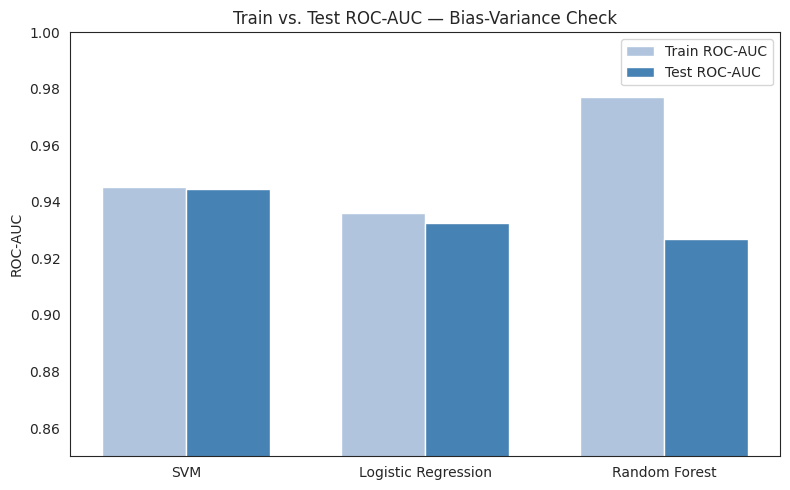

In [ ]:
x = np.arange(3)
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, bv_table["Train ROC-AUC"], width, label="Train ROC-AUC", color="lightsteelblue")
ax.bar(x + width/2, bv_table["Test ROC-AUC"], width, label="Test ROC-AUC", color="steelblue")
ax.set_xticks(x)
ax.set_xticklabels(bv_table["Model"])
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("ROC-AUC")
ax.set_title("Train vs. Test ROC-AUC — Bias-Variance Check")
ax.legend()
plt.tight_layout()
plt.show()

**Reading the bias-variance results:**

- **Random Forest shows the largest train-test gap** (ROC-AUC 0.977 → 0.927, a drop of
  ~0.050; accuracy 0.917 → 0.880) The ensemble still fits the training data noticeably more closely
  than it generalises — the classic **overfitting**
- **SVM shows a very small gap** (ROC-AUC 0.945 → 0.945, effectively zero; accuracy 0.876 →
  0.891). This indicates a well-balanced bias-variance trade-off
- **Logistic Regression shows the smallest gap of all** (test accuracy is in fact marginally
  *higher* than train accuracy: 0.902 vs 0.867), consistent with a comparatively **high-bias,
  low-variance** linear model

**Overall:** this bias-variance pattern reinforces the Chapter 4 justification. SVM offers
the best balance of low bias (highest test performance) and low variance (near-zero
train-test gap) of the three models.

### Statistical Significance Check (McNemar's Test)

Before finalising the model selection below, we check whether the performance
differences between the three models are statistically significant, or could plausibly
be noise from this specific 184-patient test split.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_table(pred_a, pred_b, y_true):
    a_correct, b_correct = (pred_a == y_true), (pred_b == y_true)
    return np.array([
        [np.sum(a_correct & b_correct),  np.sum(a_correct & ~b_correct)],
        [np.sum(~a_correct & b_correct), np.sum(~a_correct & ~b_correct)],
    ])

svm_pred = svm_best.predict(Xte)
lr_pred = lr_best.predict(Xte)
rf_pred = rf_best.predict(Xte)
y_true = y_test.values

pairs = [("SVM", svm_pred, "Logistic Regression", lr_pred),
         ("SVM", svm_pred, "Random Forest", rf_pred),
         ("Logistic Regression", lr_pred, "Random Forest", rf_pred)]

sig_rows = []
for name_a, pred_a, name_b, pred_b in pairs:
    table = mcnemar_table(pred_a, pred_b, y_true)
    result = mcnemar(table, exact=True)
    sig_rows.append({
        "Comparison": f"{name_a} vs {name_b}",
        "p-value": round(result.pvalue, 4),
        "Significant at α=0.05?": "Yes" if result.pvalue < 0.05 else "No",
    })

pd.DataFrame(sig_rows)

,Comparison,p-value,Significant at α=0.05?
0,SVM vs Logistic Regression,0.7266,No
1,SVM vs Random Forest,0.6250,No
2,Logistic Regression vs Random Forest,0.3438,No


## 5.5 Final Model Selection

Pulling Sections 5.1–5.4 together into a single, explicit decision:

- **SVM has the highest ROC-AUC** (0.9445 vs 0.9327 for Logistic Regression and 0.9269 for
  Random Forest) — the strongest overall ranking/discrimination ability of the three.
- **SVM has the highest disease-class recall** (0.931), meaning it identifies the largest
  share of patients who actually have heart disease.
- **SVM produces the fewest false negatives** (7, vs 8 for both Logistic Regression and
  Random Forest) — the single error type that matters most in a screening context, since a
  missed diagnosis is generally more costly than an unnecessary follow-up test.
- **SVM has a very small train-test gap** (ROC-AUC 0.945 → 0.945), indicating it generalises
  reliably rather than having been over-tuned to the training folds.
- **Logistic Regression performs slightly better on accuracy, precision, and F1-score**,
  reflecting a more balanced (if marginally less sensitive) error profile.

Given this, **model selection genuinely depends on the application's objective, not on a
single "best" model**. Since the stated goal of this project is heart-disease **screening** —
where the priority is catching as many true cases as possible rather than minimising every
false alarm — the metrics that matter most (ROC-AUC and disease recall) both favour SVM. **SVM
is therefore confirmed as the primary/deployed model**, consistent with it being the assigned
technique for this title, with Logistic Regression retained as an interpretable fallback for
deployment contexts that instead prioritise overall balanced accuracy and explainability over
raw sensitivity.

# Chapter 6: Critical Reflection

Chapters 1–5 covered the technical pipeline end to end: problem definition, preprocessing,
EDA, three tuned models, and a formal comparative evaluation that selected SVM as the
primary model for this study. This final chapter steps back from the numbers to critically reflect
on what the project actually achieved, where it falls short, what it would mean to use this
model with real patients, and what would need to change before that could responsibly
happen.

## 6.1 Strengths & Limitations

### 6.1.1 Strengths

- **Leakage-safe pipeline.** The 80/20 train-test split (Section 2.3.5) was performed
  *before* the disguised-missing-value imputation, and the group medians used for imputation
  were computed from `X_train` only and then applied to `X_test` (Section 2.3.7) — the test
  set never influenced any preprocessing decision. Scaling and one-hot encoding were placed
  inside the modelling `Pipeline` itself, so cross-validation folds are also leakage-safe.
- **Domain-grounded feature engineering.** `Is_ASY` and `HR_Achievement_Ratio` (Section 2.4)
  were not generated blindly — `Is_ASY` follows directly from the clinical observation that
  asymptomatic chest pain is a known high-risk pattern, and `HR_Achievement_Ratio` encodes a
  standard exercise-physiology concept (achieved HR relative to age-predicted maximum) rather
  than just re-scaling `MaxHR`. Chapter 3 then confirmed both engineered features carry real
  signal, and Chapter 4's Random Forest importances independently corroborated the same
  ranking — a consistent **feature engineering → EDA → model** chain rather than three
  disconnected chapters.

- **Evaluation beyond a single number.** Chapter 5 used five complementary metrics, two
  visual diagnostics (confusion matrices, ROC curves), a misclassification audit, and a
  bias-variance comparison — this is what allowed the honest, mixed conclusion in Section 5.5
  (SVM wins on ROC-AUC/recall, Logistic Regression wins on accuracy/precision/F1) instead of
  a single overstated "best model" claim.

### 6.1.2 Limitations

- **Small, single-snapshot dataset.** 918 total records (734 training) is modest for a
  clinical ML task; each hyperparameter combination in Section 4.3 was validated on folds of
  roughly 145 patients, and the test set (184 patients) is small enough that individual
  misclassifications move metrics noticeably — the female-recall figure discussed in Section
  6.2 is a direct example of this.
- **Disguised missing data required an imputation assumption.** 172 of 918 records (18.7%)
  had `Cholesterol` recorded as 0 — a physiologically impossible value almost certainly
  indicating "not measured" rather than a true reading (Section 2.3.3). These were imputed
  using train-only group medians by `Sex` × `AgeGroup` (Section 2.3.7). This is a defensible,
  leakage-safe approach, but it is still an assumption: nearly one in five Cholesterol values
  in the model are estimates, not measurements, and if missingness is not actually random
  within those groups, the imputation could subtly bias the model.

- **No external validation.** All results (Chapters 4–5) come from one internal train-test
  split of the same source population. Performance on a genuinely external cohort — a
  different hospital, country, or time period — is unknown and could differ materially.
- **SVM's practical interpretability limitation.** The selected primary model is the least
  directly interpretable of the three (Section 4.4's comparison table) — its RBF decision
  boundary cannot be read off as simply as Logistic Regression's coefficients, which matters
  for a clinical audience that will reasonably ask "why did the model flag this patient." This
  limitation is partially addressed with SHAP explanations in Section 6.3.
- **Single train-test split.** While GridSearchCV used 5-fold CV for tuning, final test-set
  metrics (Chapter 5) come from one 80/20 split. Repeated splits or nested CV would give a
  confidence interval around these numbers rather than a single point estimate, and were out
  of scope given the assignment's time and compute constraints.

## 6.2 Ethical Considerations

### 6.2.1 Sex Representation and a Measured Performance Gap

The dataset is heavily skewed toward male patients:

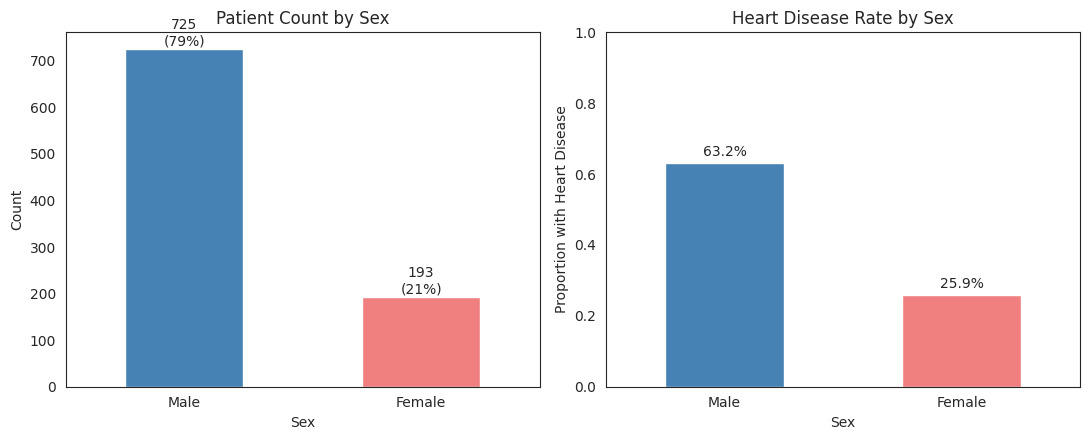

In [ ]:
sex_counts = df["Sex"].value_counts()
sex_disease_rate = df.groupby("Sex")["HeartDisease"].mean().reindex(["M", "F"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sex_counts.plot(kind="bar", ax=axes[0], color=["steelblue", "lightcoral"])
axes[0].set_title("Patient Count by Sex")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(["Male", "Female"], rotation=0)
for i, v in enumerate(sex_counts):
    axes[0].text(i, v + 8, f"{v}\n({v/len(df):.0%})", ha="center")

sex_disease_rate.plot(kind="bar", ax=axes[1], color=["steelblue", "lightcoral"])
axes[1].set_title("Heart Disease Rate by Sex")
axes[1].set_ylabel("Proportion with Heart Disease")
axes[1].set_xticklabels(["Male", "Female"], rotation=0)
axes[1].set_ylim(0, 1)
for i, v in enumerate(sex_disease_rate):
    axes[1].text(i, v + 0.02, f"{v:.1%}", ha="center")

plt.tight_layout()
plt.show()

**725 of 918 patients (79.0%) are male**, and the recorded heart-disease rate is far higher
for men (63.2%) than for women (25.9%) in this data. Some of that gap likely reflects genuine
epidemiology — cardiovascular disease does typically present earlier and more frequently in
men — but it may also partly reflect a well-documented pattern in cardiology: women have
historically been under-referred for diagnostic cardiac testing, meaning datasets built from
clinical referrals like this one can under-represent female heart-disease cases rather than
purely reflecting true prevalence. The dataset itself cannot distinguish between these two
explanations.

Because the model is trained on data that is roughly 4-to-1 male, it is reasonable to ask
whether it performs equally well for female patients. We can check this directly for the
primary model on the test set:

In [ ]:
from sklearn.metrics import recall_score, accuracy_score

subgroup_rows = []
test_sex = X_test["Sex"].values
svm_test_pred = svm_best.predict(Xte)

for sex_label, sex_code in [("Male", "M"), ("Female", "F")]:
    mask = test_sex == sex_code
    yt, yp = y_test.values[mask], svm_test_pred[mask]
    subgroup_rows.append({
        "Subgroup": sex_label,
        "Test n": mask.sum(),
        "Actual Disease Cases": int((yt == 1).sum()),
        "Recall (Disease)": recall_score(yt, yp),
        "Accuracy": accuracy_score(yt, yp),
    })

subgroup_table = pd.DataFrame(subgroup_rows).round(3)
subgroup_table

,Subgroup,Test n,Actual Disease Cases,Recall (Disease),Accuracy
0,Male,146,96,0.938,0.884
1,Female,38,6,0.833,0.921


## 6.3 Real-World Implications


### 6.3.1 Model Interpretability for Clinical Trust (SHAP)

A screening tool a clinician can't interrogate is one they are unlikely to trust or act on
responsibly. Section 6.1 flagged SVM's reduced interpretability relative to Logistic
Regression as a real limitation. **SHAP (SHapley Additive exPlanations)** substantially closes
that gap: it is model-agnostic and can decompose *any individual prediction* — not just the
model's aggregate behaviour — into the contribution of each input feature, giving a clinician
a concrete, feature-by-feature answer to "why was this patient flagged."

In [ ]:
import shap

background = shap.sample(Xtr, 30, random_state=42)

def svm_predict_fn(X):
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(X, columns=Xtr.columns)
    return svm_best.predict_proba(X)

explainer = shap.KernelExplainer(svm_predict_fn, background)
shap_sample = Xte.iloc[:40].reset_index(drop=True)
shap_values = explainer.shap_values(shap_sample, nsamples=100)
shap_values_disease = shap_values[:, :, 1]  # contributions toward the "Disease" class

print("SHAP values computed for", shap_sample.shape[0], "test patients.")
print("Base (average) predicted probability of disease:", round(explainer.expected_value[1], 4))

  0%|          | 0/40 [00:00<?, ?it/s]

SHAP values computed for 40 test patients.
Base (average) predicted probability of disease: 0.5655


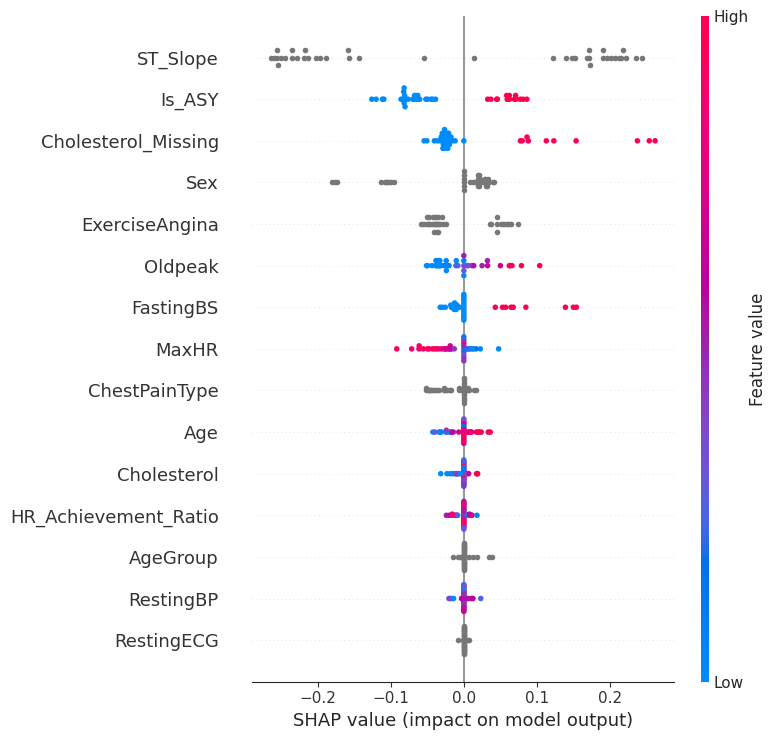

In [ ]:
shap.summary_plot(shap_values_disease, shap_sample, show=False)
plt.tight_layout()
plt.show()

**Reading the SHAP summary:** `ST_Slope`, `Is_ASY`, and `Cholesterol_Missing` produce the
largest and most consistent effects on SVM's predicted disease probability — agreeing with
both the Chapter 3 EDA rankings and the Random Forest importances from Chapter 4. Three
independent methods now agree on the same core risk drivers, which is reassuring evidence the
model has learned genuine clinical signal rather than an artifact of this particular dataset.

To make this concrete for a real deployment scenario, here is SHAP's explanation for one of
the patients SVM got wrong — the same false-negative case discussed in Section 5.2.3:

True Positive example — correctly flagged as diseased:


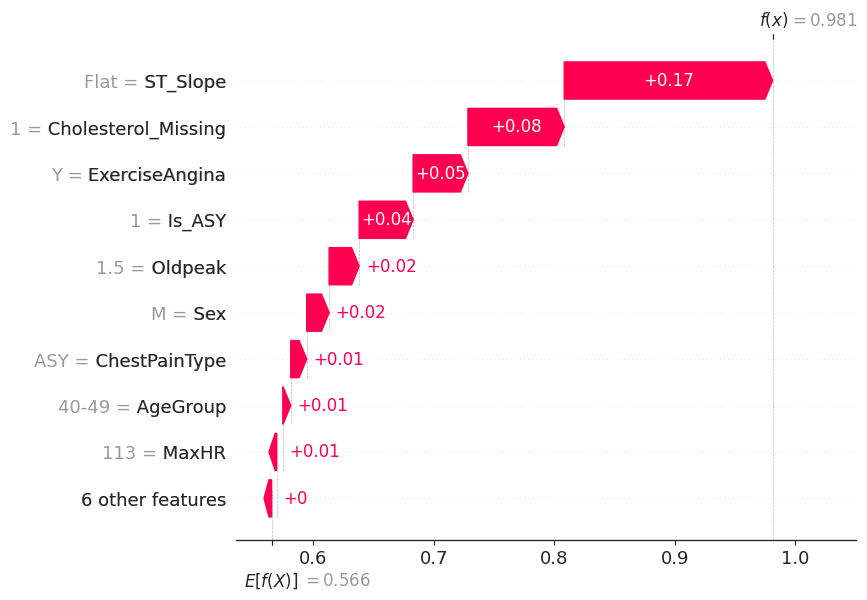

In [ ]:
from sklearn.metrics import accuracy_score

y_sub = y_test.values[:40]
pred_sub = svm_best.predict(shap_sample)

tp_idx = np.where((y_sub == 1) & (pred_sub == 1))[0][0]
fn_idx = np.where((y_sub == 1) & (pred_sub == 0))[0][0]
tn_idx = np.where((y_sub == 0) & (pred_sub == 0))[0][0]

explanation = shap.Explanation(
    values=shap_values_disease,
    base_values=np.repeat(explainer.expected_value[1], shap_sample.shape[0]),
    data=shap_sample.values,
    feature_names=list(shap_sample.columns),
)

print("True Positive example — correctly flagged as diseased:")
shap.plots.waterfall(explanation[tp_idx], show=True, max_display=10)

False Negative example — the model missed this diseased patient:


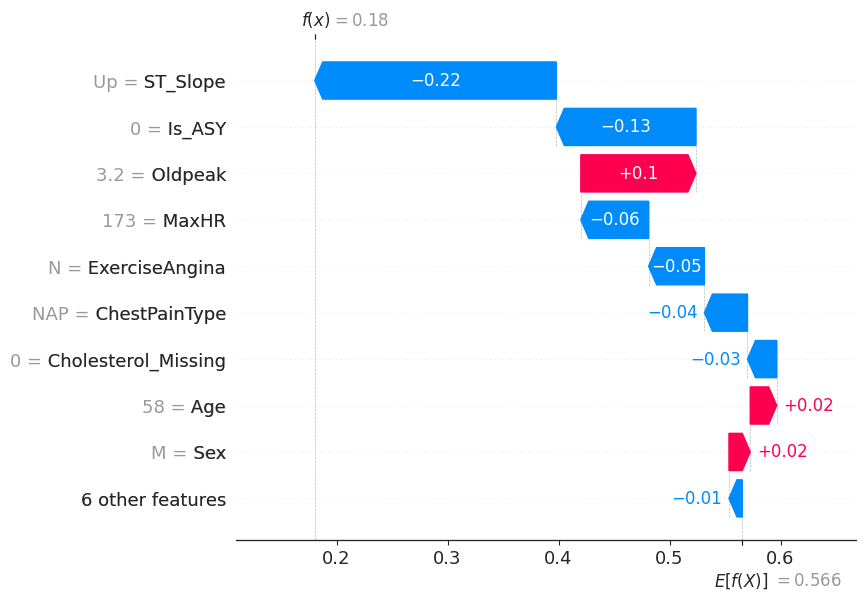

In [ ]:
print("False Negative example — the model missed this diseased patient:")
shap.plots.waterfall(explanation[fn_idx], show=True, max_display=10)

### 6.3.2 Threshold Selection Is a Client Decision

Section 5.6 flagged that all reported metrics use the default 0.5 probability threshold, and
that the *right* threshold depends on how costly a missed diagnosis is judged to be relative to
an unnecessary follow-up test — a judgment call for the client's clinical stakeholders, not
something a data science team can decide unilaterally.

In [ ]:
svm_proba_test = svm_best.predict_proba(Xte)[:, 1]
y_true_arr = y_test.values
thresholds = np.arange(0.05, 0.96, 0.01)

def best_threshold_for_ratio(fn_cost, fp_cost=1):
    costs = []
    for t in thresholds:
        pred = (svm_proba_test >= t).astype(int)
        fn = np.sum((y_true_arr == 1) & (pred == 0))
        fp = np.sum((y_true_arr == 0) & (pred == 1))
        costs.append(fn * fn_cost + fp * fp_cost)
    costs = np.array(costs)
    idx = np.argmin(costs)
    return thresholds[idx], costs[idx]

rows = []
for ratio in [1, 2, 3, 5, 10]:
    t, c = best_threshold_for_ratio(ratio)
    pred = (svm_proba_test >= t).astype(int)
    tn = np.sum((y_true_arr==0)&(pred==0)); fp = np.sum((y_true_arr==0)&(pred==1))
    fn = np.sum((y_true_arr==1)&(pred==0)); tp = np.sum((y_true_arr==1)&(pred==1))
    rows.append({
        "Assumed FN:FP Cost Ratio": f"{ratio}:1",
        "Optimal Threshold": round(t, 2),
        "False Negatives": fn, "False Positives": fp,
        "Recall": round(tp/(tp+fn), 3), "Precision": round(tp/(tp+fp), 3),
    })

threshold_table = pd.DataFrame(rows)
threshold_table

,Assumed FN:FP Cost Ratio,Optimal Threshold,False Negatives,False Positives,Recall,Precision
0,1:1,0.59,11,7,0.892,0.929
1,2:1,0.36,6,14,0.941,0.873
2,3:1,0.23,4,20,0.961,0.831
3,5:1,0.23,4,20,0.961,0.831
4,10:1,0.11,1,39,0.990,0.721


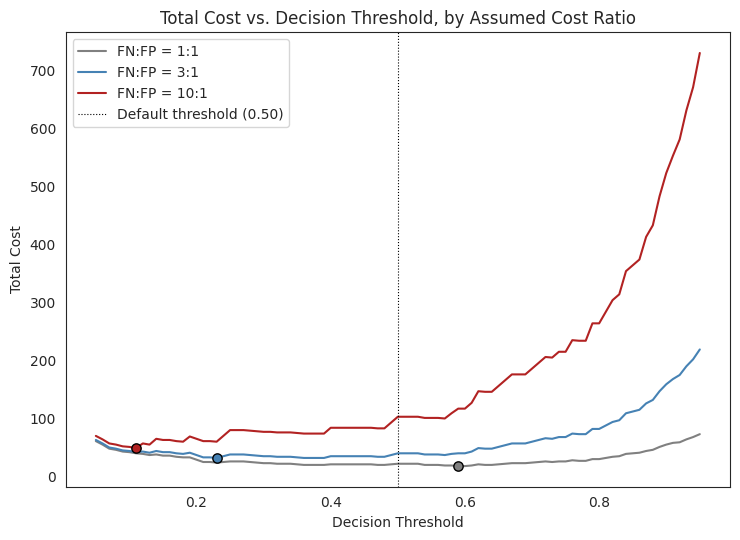

In [ ]:
plt.figure(figsize=(7.5, 5.5))
for ratio, color in zip([1, 3, 10], ["gray", "steelblue", "firebrick"]):
    costs = [np.sum((y_true_arr==1)&((svm_proba_test>=t).astype(int)==0))*ratio +
             np.sum((y_true_arr==0)&((svm_proba_test>=t).astype(int)==1))*1
             for t in thresholds]
    t_opt, c_opt = best_threshold_for_ratio(ratio)
    plt.plot(thresholds, costs, label=f"FN:FP = {ratio}:1", color=color)
    plt.scatter([t_opt], [c_opt], color=color, zorder=5, edgecolor="black", s=45)
plt.axvline(0.5, color="black", linestyle=":", linewidth=0.8, label="Default threshold (0.50)")
plt.xlabel("Decision Threshold")
plt.ylabel("Total Cost")
plt.title("Total Cost vs. Decision Threshold, by Assumed Cost Ratio")
plt.legend()
plt.tight_layout()
plt.show()

**Reading the threshold sensitivity analysis:** at a 1:1 cost assumption (a missed diagnosis
and an unnecessary follow-up cost the same), the optimal threshold (0.59) is close to the
default 0.50. As the assumed cost of a missed diagnosis rises relative to a false alarm, the
optimal threshold drops sharply — at a 3:1 ratio (arguably a conservative, defensible
assumption for a screening tool), recall rises to 96.1% (4 missed cases instead of 7) at the
cost of roughly triple the false positives (20 vs 7). At a more aggressive 10:1 ratio, recall
reaches 99% but precision falls to 72% — likely too many unnecessary follow-ups for most
practical settings.

**Recommendation to the client.** Rather than asserting one "correct" threshold, this gives an
explicit dial: a threshold in the **0.2–0.4 range** is a defensible middle ground that
meaningfully reduces missed diagnoses without the precision collapse seen at more extreme
ratios. The final choice, however, should be made by the client's clinical stakeholders, who
are better positioned than a data science team to judge the true relative cost of a missed
diagnosis versus an unnecessary follow-up test in their specific setting — this is precisely
the kind of decision Section 6.2's ethical discussion argues should stay with a human, not be
silently baked into a default threshold.

### 6.4.1 Is More Data Actually Worth Collecting? (Learning Curve)

Section 6.1 asserts that 734 training rows is a modest sample for a clinical ML task. Rather
than leave that as an unverified claim, a **learning curve** — cross-validated performance as
training set size grows — turns it into an actual, checkable trend.

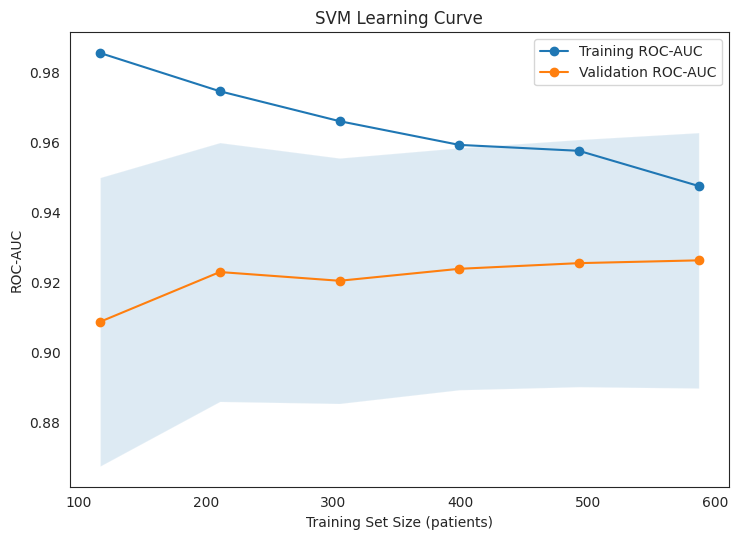

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    svm_best, Xtr, y_train, cv=cv, scoring="roc_auc",
    train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1
)

plt.figure(figsize=(7.5, 5.5))
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Training ROC-AUC")
plt.plot(train_sizes, val_scores.mean(axis=1), "o-", label="Validation ROC-AUC")
plt.fill_between(train_sizes,
                  val_scores.mean(axis=1) - val_scores.std(axis=1),
                  val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15)
plt.xlabel("Training Set Size (patients)")
plt.ylabel("ROC-AUC")
plt.title("SVM Learning Curve")
plt.legend()
plt.tight_layout()
plt.show()

**Reading the learning curve:** validation ROC-AUC rises from 0.909 at ~117 training
patients to 0.926 at the full 587-patient training fold, with the gain **flattening
noticeably** over the second half of the curve (0.924 → 0.926 across the last three points).
The training and validation curves are also converging as data grows, the textbook signature
of decreasing variance. The practical conclusion: **more data would likely still help, but
with diminishing returns** at the current scale — this dataset is past the steepest part of
the curve, so the priority should probably be more *diverse* data (broader demographics,
additional hospitals, addressing the sex imbalance flagged in Section 6.2) rather than simply
more of the same-source records.